# SENTINEL: An Intelligent POMDP-Based Inventory Management and Decision Support System Under Uncertainty

*Bayesian Belief-State Estimation, Adaptive Decision Policies and Interactive Supply Chain Simulation.*

**Course:** Reasoning and Decision Making Under Uncertainty (RDMU) · **Assignment:** Session III, Lab Activity – Exercise 3
**Companion deliverable:** the SENTINEL AI dashboard (`streamlit run dashboard/app.py`), which imports the same Python engine used below.

> **Status of every number in this notebook.** All transition probabilities, observation likelihoods, costs, inventory thresholds and performance results are **synthetic simulation assumptions or synthetic simulation output**. Nothing here is estimated from, or validated against, real supply-chain data. Published research is cited only for concepts and for the few empirical facts stated explicitly as such.

**What this notebook shows.** An agent cannot see the true inventory condition. It keeps a probability distribution over three hidden conditions (its *belief state*), updates that distribution with Bayes' rule whenever sensor, supplier, demand or system alerts arrive, and recommends the operational action with the lowest expected cost. The policy is a transparent **myopic one-step expected-cost rule**. It is not a globally optimal infinite-horizon POMDP solver, and the notebook says where that matters.

To keep five kinds of statement apart, the notebook labels them:

| Label | Meaning |
|---|---|
| **Published finding** | A result reported in the cited literature |
| **Derivation** | Mathematics that follows from the definitions |
| **Synthetic assumption** | A parameter chosen for this teaching simulation |
| **Implementation decision** | A design choice made in the code |
| **Experimental result** | Output of the synthetic simulation in this notebook |

## Table of contents

1. [Project introduction](#1.-Project-introduction)
2. [Supply chain environment](#2.-Supply-chain-environment)
3. [Fundamentals of MDP and POMDP](#3.-Fundamentals-of-MDP-and-POMDP)
4. [Mathematical POMDP formulation](#4.-Mathematical-POMDP-formulation)
5. [Python environment and data generation](#5.-Python-environment-and-data-generation)
6. [Implementation of the belief-state engine](#6.-Implementation-of-the-belief-state-engine)
7. [Intelligent decision policy](#7.-Intelligent-decision-policy)
8. [Dynamic alert simulation](#8.-Dynamic-alert-simulation)
9. [Performance evaluation](#9.-Performance-evaluation)
10. [Data visualisations](#10.-Data-visualisations)
11. [Discussion and interpretation](#11.-Discussion-and-interpretation)
12. [Limitations and future improvements](#12.-Limitations-and-future-improvements)
13. [Final conclusion](#13.-Final-conclusion)
14. [References](#References)

## 1. Project introduction

### 1.1 Assignment context

The lab brief asks for an interactive web-based dashboard, built with Python and HTML, that demonstrates how an AI agent **updates its belief state and changes its decision policy when new alerts are received**, in an inventory-management setting inspired by the "MDP Belief State (POMDP)" infographic. The infographic's loop has six stages: real-world environment → partial observation → belief state → policy → action → reward, after which a new observation arrives and the belief is updated again.

### 1.2 Problem statement

In real supply chains, the true inventory condition is often unknown. Decision-makers see it only through sensors, supplier updates, demand signals and system alerts, each of which is incomplete and sometimes wrong. An intelligent agent therefore has to do two things: estimate the probability of each inventory condition, and choose an operational action that is sensible given that uncertainty.

### 1.3 Objectives

1. Formulate the problem as a POMDP $(S, A, T, O, Z, R, \gamma)$ with every component defined before it is used.
2. Implement an exact Bayes filter with a separate prediction and correction stage.
3. Implement a transparent expected-cost policy that evaluates all four actions and explains its choice.
4. Simulate alerts from four channels and show how belief and recommendation respond.
5. Evaluate beliefs and policies with proper scoring rules, baselines, confidence intervals and model-mismatch experiments.
6. Share one engine between this notebook and the dashboard, and prove that they agree numerically.

### 1.4 Expected outcomes

By the end of this notebook, a reader should be able to explain, with numbers, why a given alert moved the belief by a given amount, why the recommendation did or did not change, and what the approach cannot do.

### 1.5 Why inventory management involves uncertainty

A stock record is a claim about the world, not the world. **Published finding:** in an audit of nearly 370,000 inventory records from 37 stores of one retailer, DeHoratius and Raman (2008) found 65% of records to be inaccurate. That figure describes one retailer and should not be generalised to all supply chains, but it establishes the premise: the recorded state and the true state can, and often do, differ. Demand fluctuates, deliveries slip, and sensors fail, so the true condition has to be inferred.

### 1.6 Why a belief-state model is appropriate

If the state cannot be observed, acting on a single "best guess" throws information away: a 55% chance of healthy stock and a 99% chance are very different situations. A **belief state** keeps the whole probability distribution. **Published finding:** the belief is a sufficient statistic for the entire history of actions and observations, provided it is computed with the correct model (Åström, 1965; Kaelbling et al., 1998). In the inventory literature, the same idea appears as a Bayesian distribution over physical inventory that summarises past observations (DeHoratius et al., 2008).

### Notebook set-up

The next cell locates the project root, imports the **shared engine** from `src/` (the same modules the dashboard imports) and fixes the random seed. Section 5 describes the environment and data generation in detail; the imports sit here so that the diagrams in Sections 2–4 are produced by the shared code.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import plotly
import plotly.io as pio
import scipy
from IPython.display import Markdown, display

# --- locate the project root (works from notebooks/ or from the root) ---------
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "pomdp_engine.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "src" / "pomdp_engine.py").exists(), "Run this notebook from inside the SENTINEL project."
sys.path.insert(0, str(ROOT))

# --- the shared engine: one implementation for notebook and dashboard --------
from src import visualization as viz
from src.belief_updater import (bayes_update, belief_concentration, correct, correct_sequential,
                                predict, validate_belief)
from src.config import (ACTION_KEYS, ACTION_SHORT, ACTIONS, CHANNEL_KEYS, CHANNELS, COST_UNIT,
                        DEMAND_MEAN_UNITS, DEMAND_SD_UNITS, INVENTORY_BANDS, STATES, STATE_DESCRIPTIONS,
                        ACTION_DESCRIPTIONS, check_inventory_bands, default_config, inventory_band_label)
from src.cost_model import CostModel
from src.decision_policy import (BeliefMyopicPolicy, FixedPolicy, InfographicThresholdPolicy, OraclePolicy,
                                 PeriodicReorderPolicy, QMDPPolicy, RecordTrustingPolicy, evaluate_actions,
                                 explain_decision, policy_region_grid)
from src.inventory_simulator import (AgentModels, EnvironmentOptions, evaluate_policies,
                                     generate_event_dataset, run_episode, service_profile)
from src.metrics import (BELIEF_COLUMNS, brier_score, brier_scores, calibration_table,
                         expected_calibration_error, gap_closed, log_loss, map_accuracy,
                         mean_confidence_interval, paired_difference, summarise_replications)
from src.observation_model import ObservationModel
from src.pomdp_engine import SentinelEngine, format_belief
from src.scenarios import CROSS_CHECK_SCENARIOS, NOTEBOOK_SCENARIOS, SCENARIOS, replay_with_primitives
from src.transition_model import TransitionModel

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30, "display.width", 180, "display.precision", 4)

SEED = 42                                   # fixed seed: every result below is reproducible
cfg = default_config()
assert cfg.validate() == [], cfg.validate()
transition_model = TransitionModel.from_config(cfg)
observation_model = ObservationModel.from_config(cfg)
cost_model = CostModel.from_config(cfg)

CHARTS = ROOT / "outputs" / "charts"
CHARTS.mkdir(parents=True, exist_ok=True)

# --- chart display: interactive Plotly, plus a static PNG copy when Chrome/Kaleido is available ----
pio.renderers.default = "plotly_mimetype+notebook_connected"
STATIC_EXPORT = False
try:
    import plotly.graph_objects as go
    try:                                    # keep one headless browser alive: much faster PNG export
        import kaleido
        warnings.filterwarnings("ignore", message=".*kopts argument is ignored.*")
        kaleido.start_sync_server(silence_warnings=True)
    except Exception:
        pass
    pio.to_image(go.Figure(), format="png", width=60, height=40)
    pio.renderers["png"].width = 1000
    pio.renderers.default = "plotly_mimetype+notebook_connected+png"
    STATIC_EXPORT = True
except Exception as error:                  # no Chrome/Kaleido: charts stay interactive-only
    print("Static PNG export unavailable; charts remain interactive.", type(error).__name__)


def show(fig, name=None):
    # Display a figure and, when possible, save a PNG copy to outputs/charts/.
    fig.show()
    if STATIC_EXPORT and name:
        try:
            fig.write_image(str(CHARTS / f"{name}.png"), width=1100, scale=1)
        except Exception as error:
            print("PNG copy skipped:", type(error).__name__)


def pct(frame, columns=None, digits=1):
    # Format probability columns as percentages for display.
    columns = list(columns if columns is not None else frame.columns)
    return frame.style.format({c: "{:." + str(digits) + "%}" for c in columns})


print(f"Project root : {ROOT.name}")
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | pandas {pd.__version__} | "
      f"SciPy {scipy.__version__} | Plotly {plotly.__version__}")
print(f"Random seed  : {SEED} | static PNG export: {STATIC_EXPORT}")

Project root : SENTINEL_POMDP_PROJECT
Python 3.13.18 | NumPy 2.5.3 | pandas 3.0.5 | SciPy 1.18.1 | Plotly 7.1.0
Random seed  : 42 | static PNG export: True


## 2. Supply chain environment

### 2.1 The simulated supply chain

The simulation models one stocked item at one warehouse over a sequence of operating days (one *period* = one day).

| Element | Role in the simulation |
|---|---|
| **Suppliers** | Deliver replenishment. Standard orders have a normal lead time; expedited orders arrive faster at a premium. Deliveries can be late, partial or cancelled, which the agent hears about through *supplier updates*. A supplier-risk parameter $\rho$ lets an order fail to land. |
| **Warehouse** | Holds up to 1,000 units (synthetic assumption). The agent never sees any unit figure. |
| **Inventory levels** | Modelled as three hidden conditions: Healthy, Low, Critical. Each is associated with a unit band, Healthy [600, 1,000], Low [250, 600) and Critical [0, 250), used only to produce unit proxies for evaluation. The bands do not overlap and leave no gaps over the range [0, 1,000]. |
| **Incoming replenishment** | Raises the probability of moving to a better condition; how much depends on the action executed. |
| **Demand fluctuations** | Daily demand is drawn around 180, 240, 310 or 420 units depending on the demand level; the agent sees only a noisy *demand signal*. |
| **Sensor observations** | Shelf or bin sensors report normal / low / critical readings and occasionally malfunction. |
| **Supplier communications** | On-schedule, minor delay, significant delay, partial shipment, cancellation. |
| **System alerts** | The warehouse monitoring system raises anomaly, low-stock and critical-stock warnings. |
| **Operational risks** | Stock-outs (demand exceeds the period's inventory snapshot), service-level loss, surplus holding cost from ordering when stock is already healthy, and wasted premium on unnecessary expediting. |

**Implementation decision: state-conditioned inventory snapshots, not a stock ledger.** The only quantity with dynamics is the three-state hidden condition, which moves according to the transition model. To express stock-outs and fill rate in units, the simulator draws a **synthetic inventory snapshot** in every period, uniformly inside the current state's unit band, together with an independent demand. Snapshots are **not rolled forward**: there is no balance equation of the form *next stock = stock − demand + deliveries*, so consecutive snapshots are independent given the hidden states. Stock-out frequency and fill rate are computed period by period from snapshot and demand. They are proxies that make the three-state abstraction measurable; they are not the output of a physically continuous inventory simulation. The agent never receives any of these quantities: the only thing passed from the simulator to the agent is the list of observations.

### 2.2 System architecture

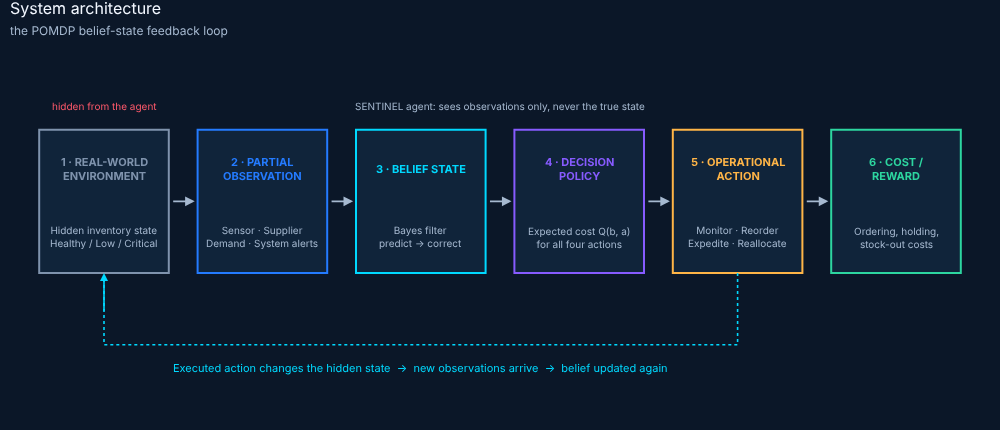

In [2]:
show(viz.fig_architecture(), "01_system_architecture")

**Reading the diagram.** Box 1 is the only place where the truth lives. Boxes 3–5 are the agent, which is given observations and nothing else. The dotted return path is what makes this a *feedback* loop: an executed action changes the hidden state, the changed state produces new observations, and those observations update the belief on which the next decision is based. The cost in box 6 is the consequence used to compare actions; it is not shown to the agent as a signal about the state.

**Link to RDMU.** This is the standard agent–environment loop under partial observability: the agent must *reason* (boxes 2–3) before it can *decide* (boxes 4–5).

## 3. Fundamentals of MDP and POMDP

### 3.1 Markov Decision Process (MDP)

An MDP describes sequential decisions when the state is **fully observable**. It is a tuple $(S, A, T, R, \gamma)$: states $S$, actions $A$, transition probabilities $T(s' \mid s, a)$, a reward (or cost) function $R$ and a discount factor $\gamma$. Because the agent sees $s$, a policy is simply a mapping from states to actions, $\pi: S \to A$.

### 3.2 Partially Observable MDP (POMDP)

A POMDP additionally assumes that the agent **cannot directly observe the state**. It receives observations $o \in O$ generated with probability $Z(o \mid s')$ and must act on those. The tuple becomes

$$\text{POMDP} = (S, A, T, O, Z, R, \gamma).$$

| Concept | Meaning | In SENTINEL |
|---|---|---|
| **Hidden state** $s$ | The true condition of the world; never shown to the agent | Healthy / Low / Critical inventory |
| **Observation** $o$ | A noisy signal correlated with the state | A sensor reading, supplier update, demand signal or system alert |
| **Action** $a$ | What the agent can do | Monitor, reorder, expedite, reallocate |
| **Transition probability** $T(s' \mid s, a)$ | How the hidden state evolves after an action | Four 3×3 matrices |
| **Observation likelihood** $Z(o \mid s')$ | How probable each signal is in each state | One matrix per channel |
| **Reward / cost** $R = -C$ | Consequence of acting | Ordering, holding and stock-out costs |
| **Belief state** $b$ | Probability distribution over hidden states | $b = [P(\text{Healthy}), P(\text{Low}), P(\text{Critical})]$ |

### 3.3 Fully observable versus partially observable

| | MDP | POMDP |
|---|---|---|
| What the agent knows | The state $s$ | A belief $b(s)$ |
| Policy | $\pi(s)$ | $\pi(b)$ |
| Effect of an action | Changes the state | Changes the state **and** what will be learned next |
| Difficulty | Polynomial-time solvable | Finite-horizon planning is PSPACE-complete (Papadimitriou & Tsitsiklis, 1987) |

**Published finding.** Because the belief is a sufficient statistic, a POMDP can be rewritten as an MDP whose "state" is the belief itself, the *belief MDP*; its optimal finite-horizon value function is piecewise linear and convex in the belief (Smallwood & Sondik, 1973; Kaelbling et al., 1998). Solving that belief MDP exactly is intractable in general, which is why practical systems use approximations such as QMDP (Littman et al., 1995) or point-based solvers such as SARSOP (Kurniawati et al., 2008).

### 3.4 Why conventional inventory tracking is not enough

A conventional system stores one number per item and treats it as fact. It has no way to express "the record says 700 units, but a supplier cancellation and a demand surge make that doubtful". It cannot weigh a reliable sensor against an unreliable one, and it cannot tell a manager how *sure* it is. A belief state can express all three because its purpose is to represent uncertainty.

## 4. Mathematical POMDP formulation

Every component is defined here **before** it is used. All numerical values are **synthetic assumptions**, centralised in `src/config.py`.

### 4.1 Timing convention

One period $t$ runs in this order, and the same convention is used by the notebook, the simulator and the dashboard:

1. The agent holds belief $b_t$ and evaluates $Q(b_t, a)$ for every action. This yields a **recommendation**; nothing changes in the world.
2. An action $a_t$ is **executed** (the recommendation, or an operator override).
3. The hidden state moves: $s_{t+1} \sim T(\cdot \mid s_t, a_t)$.
4. The cost $C(s_t, a_t, s_{t+1})$ is incurred; the reward is $R = -C$.
5. Each channel $k$ emits an observation $o^k_{t+1} \sim Z_k(\cdot \mid s_{t+1})$.
6. The belief is updated with **one** prediction and **one** joint correction.

Alerts injected by hand between two executed actions belong to the current period. They trigger only the correction, never a transition, because no action has been executed.

### 4.2 States $S$ and actions $A$

In [3]:
states_table = pd.DataFrame({
    "State": STATES,
    "Description": STATE_DESCRIPTIONS,
    "Unit band for the evaluation snapshot (hidden)": [inventory_band_label(i) for i in range(len(STATES))],
})
actions_table = pd.DataFrame({
    "Action": ACTIONS,
    "When it is appropriate": ACTION_DESCRIPTIONS,
    f"Direct cost ({COST_UNIT})": cfg.action_cost,
})
display(states_table.style.hide(axis="index"))
display(actions_table.style.hide(axis="index").format({f"Direct cost ({COST_UNIT})": "{:.1f}"}))

State,Description,Unit band for the evaluation snapshot (hidden)
Healthy,Adequate inventory available; no immediate replenishment concern.,"[600, 1,000]"
Low,Inventory is below the preferred operating level; replenishment may become necessary.,"[250, 600)"
Critical,Inventory is dangerously low; stock-out and service disruption risk.,"[0, 250)"


Action,When it is appropriate,Direct cost (SCU)
Continue Monitoring,Keep observing without committing inventory expenditure. Appropriate while belief mass sits on Healthy and the expected shortage cost is small.,0.0
Standard Reorder,Place a normal replenishment order with standard lead time. Appropriate when Low inventory is the most likely condition.,15.0
Expedite Supplier Delivery,Pay a premium for fast replenishment. Appropriate when the probability of Critical inventory is high enough that the stock-out penalty dominates.,40.0
Adjust Production / Reallocate Stock,"Re-plan production or move stock between locations. Uses internal capacity, so it does not depend on the external supplier; appropriate for a mixed Low/Critical picture or when supplier risk is high.",22.0


The four actions correspond to standard operational levers in inventory management: placing no order, regular replenishment, an emergency or expedited supply mode, and lateral reallocation or production re-planning (Silver et al., 2017). That mapping is this project's design rationale; the cost values themselves are synthetic.

### 4.3 Initial belief $b_0$

$$b_0 = [0.60,\ 0.30,\ 0.10], \qquad \sum_s b(s) = 1, \qquad 0 \le b(s) \le 1 .$$

These are the **illustrative starting probabilities printed on the lecture infographic**. They are not real-world inventory statistics. It is configurable through `cfg.initial_belief` and through the dashboard's What-If Lab.

b0 = [0.6 0.3 0.1] | sums to 0.9999999999999999 | belief concentration = 0.183


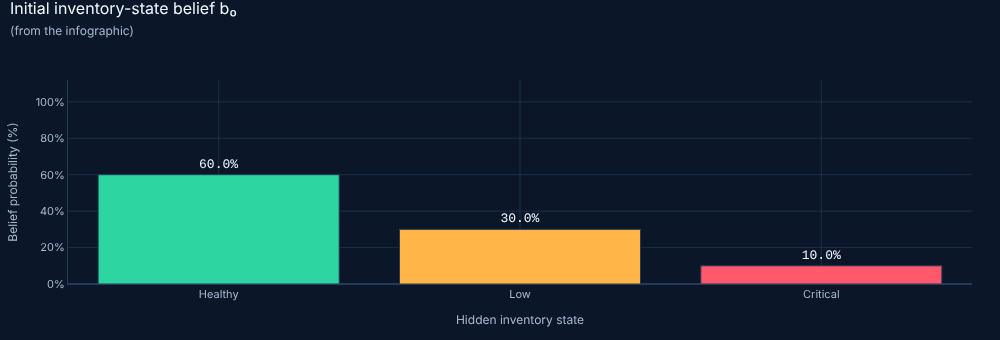

In [4]:
b0 = validate_belief(cfg.initial_belief)            # raises if not a valid distribution
print("b0 =", b0, "| sums to", b0.sum(), "| belief concentration =", round(belief_concentration(b0), 3))
show(viz.fig_belief_distribution(b0, "Initial inventory-state belief b₀ (from the infographic)"),
     "02_initial_belief")

**Interpretation.** The agent starts fairly optimistic but far from certain: a 40% chance that stock is below target, including a 10% chance that it is critical. The *belief concentration* index ($1 - H(b)/\ln 3$, where $H$ is Shannon entropy) is low, which says the distribution is diffuse. This index measures how peaked the belief is; it is not the probability that the belief is right.

### 4.4 Transition model $T(s' \mid s, a)$

$T(s' \mid s, a)$ is the probability that the hidden state moves from $s$ to $s'$ after action $a$. There is one matrix per action; rows are the current state and each row sums to 1.

**Synthetic assumptions behind the numbers.**

- *Continue Monitoring:* demand depletes stock, so states drift downwards, and Critical is persistent (90% chance of staying Critical) because nothing is arriving.
- *Standard Reorder:* good recovery from Low, only partial recovery from Critical within one period (normal lead time).
- *Expedite Supplier Delivery:* the strongest recovery, especially from Critical.
- *Adjust Production / Reallocate Stock:* quick partial relief from internal sources; stronger than a standard reorder but weaker than expediting.

Two optional environment modifiers generate the *effective* matrices: supplier delivery risk $\rho$ (a reorder or expedite fails to land with probability $\rho$: $T'_a = (1-\rho)T_a + \rho\,T_{\text{monitor}}$) and demand volatility $\kappa$ (one extra level of depletion with probability $\kappa$: $T^{\text{eff}}_a = T'_a D(\kappa)$). Both default to 0, and both preserve row sums.

In [5]:
for key, name in zip(ACTION_KEYS, ACTIONS):
    matrix = transition_model.matrix(key)
    assert np.allclose(matrix.sum(axis=1), 1.0) and (matrix >= 0).all()      # every row is a distribution
    print(f"{name}  (row sums: {matrix.sum(axis=1).round(6)})")
    display(pct(transition_model.as_frame(key)))

Continue Monitoring  (row sums: [1. 1. 1.])


,to Healthy,to Low,to Critical
from Healthy,85.0%,13.0%,2.0%
from Low,5.0%,70.0%,25.0%
from Critical,1.0%,9.0%,90.0%


Standard Reorder  (row sums: [1. 1. 1.])


,to Healthy,to Low,to Critical
from Healthy,93.0%,6.0%,1.0%
from Low,50.0%,42.0%,8.0%
from Critical,15.0%,45.0%,40.0%


Expedite Supplier Delivery  (row sums: [1. 1. 1.])


,to Healthy,to Low,to Critical
from Healthy,96.0%,3.5%,0.5%
from Low,75.0%,22.0%,3.0%
from Critical,60.0%,32.0%,8.0%


Adjust Production / Reallocate Stock  (row sums: [1. 1. 1.])


,to Healthy,to Low,to Critical
from Healthy,90.0%,9.0%,1.0%
from Low,60.0%,34.0%,6.0%
from Critical,25.0%,50.0%,25.0%


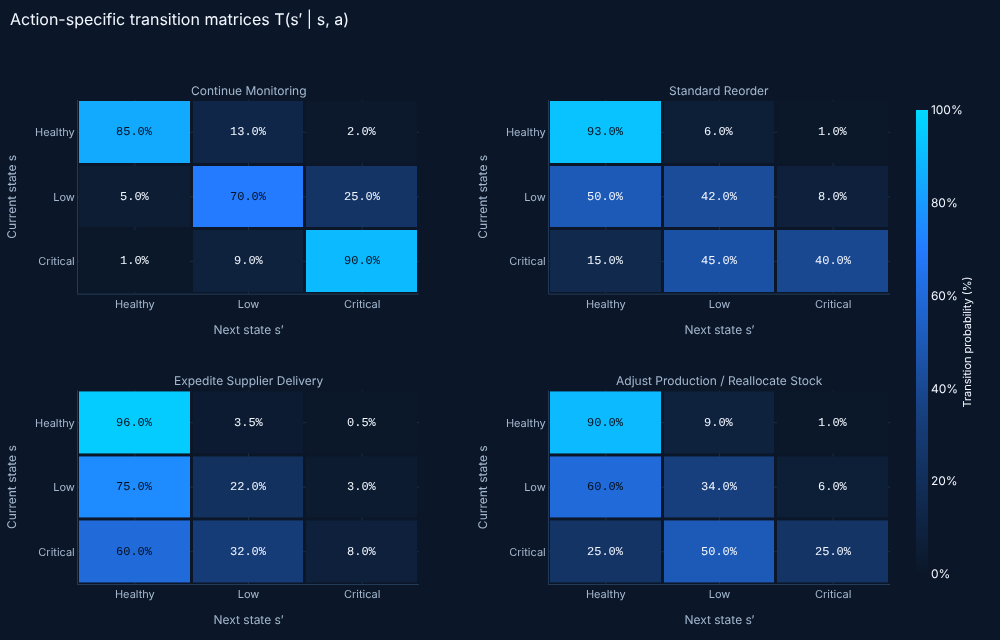

In [6]:
show(viz.fig_transition_grid(transition_model.tensor()), "03_transition_heatmaps")

**Interpretation.** Read the bottom row of each panel (current state Critical). Under monitoring, the system stays Critical 90% of the time; a standard reorder cuts that to 40%, reallocation to 25% and expediting to 8%. This ordering is what gives the four actions different value at different beliefs: the more probability the agent puts on Critical, the more the stronger (and dearer) actions are worth. The top rows show the downside of over-reacting: when stock is already Healthy, every action leaves it Healthy with high probability, so the extra spend buys almost nothing.

### 4.5 Observations $O$ and likelihoods $Z(o \mid s)$

There are four channels, each with its own alphabet and its own likelihood matrix $Z_k(o \mid s)$, whose rows (one per hidden state) sum to 1.

**Likelihood is not belief.** $Z(o \mid s)$ answers "if the state were $s$, how probable is this alert?". The belief answers the reverse question, "given this alert, how probable is each state?". Bayes' rule converts one into the other. *An observation is evidence; it is not the state.*

**Reliability (synthetic assumption, contamination mixture).** A channel with reliability $r$ reports a genuine reading with probability $r$ and state-independent noise otherwise:

$$Z_r(o \mid s) = r\,Z(o \mid s) + (1-r)\,\frac{1}{|O|} .$$

This is Huber's (1964) contamination idea applied to a discrete channel, and it matches how range-sensor models in robotics add a uniform component for unexplainable measurements (Thrun et al., 2005). Three properties follow (**derivation**, verified by unit tests): $Z_r(\cdot \mid s)$ is still a valid distribution, so the simulator can sample from exactly the model the agent assumes; at $r=1$ it is the nominal model; at $r=0$ it is identical for every state, so the observation cannot move the belief.

**Severity** is modelled by giving each severity level its own observation symbol and likelihood column (for example *minor* versus *significant* delay), so severity enters through Bayes' rule and not through an ad hoc multiplier.

In [7]:
for key in CHANNEL_KEYS:
    nominal = pd.DataFrame(observation_model.nominal[key], index=[f"state = {s}" for s in STATES],
                           columns=CHANNELS[key]["observations"])
    assert np.allclose(nominal.sum(axis=1), 1.0)
    print(f"{CHANNELS[key]['label']} — nominal likelihoods Z(o | s); default reliability "
          f"{cfg.reliability[key]:.0%}")
    display(pct(nominal))

Sensor readings — nominal likelihoods Z(o | s); default reliability 90%


,Normal inventory reading,Low inventory reading,Critical inventory warning,Sensor malfunction / unreliable reading
state = Healthy,80.0%,12.0%,3.0%,5.0%
state = Low,15.0%,68.0%,12.0%,5.0%
state = Critical,4.0%,21.0%,70.0%,5.0%


Supplier updates — nominal likelihoods Z(o | s); default reliability 85%


,Delivery on schedule,Minor delivery delay,Significant delivery delay,Partial shipment,Supplier cancellation
state = Healthy,70.0%,17.0%,5.0%,6.0%,2.0%
state = Low,38.0%,27.0%,15.0%,14.0%,6.0%
state = Critical,15.0%,22.0%,28.0%,20.0%,15.0%


Demand signals — nominal likelihoods Z(o | s); default reliability 80%


,Normal demand,Moderately elevated demand,High demand,Unexpected demand surge
state = Healthy,62.0%,24.0%,10.0%,4.0%
state = Low,35.0%,32.0%,22.0%,11.0%
state = Critical,18.0%,26.0%,32.0%,24.0%


System alerts — nominal likelihoods Z(o | s); default reliability 90%


,No anomaly,Inventory anomaly detected,Replenishment / low-stock warning,Critical stock warning,Monitoring system malfunction
state = Healthy,78.0%,9.0%,7.0%,2.0%,4.0%
state = Low,22.0%,20.0%,44.0%,10.0%,4.0%
state = Critical,6.0%,16.0%,24.0%,50.0%,4.0%


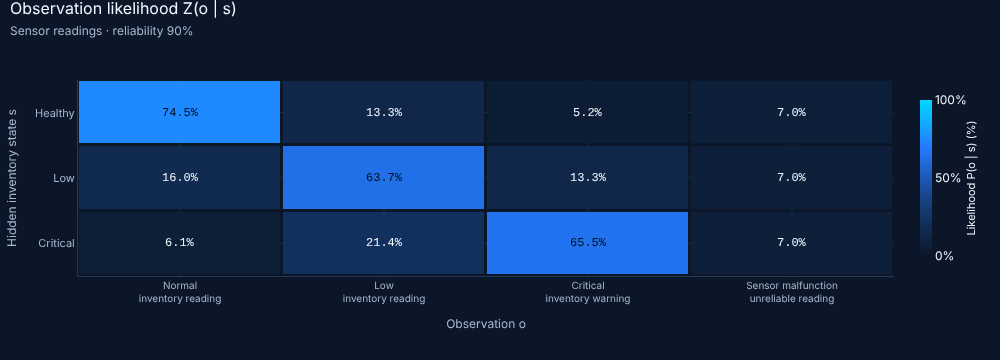

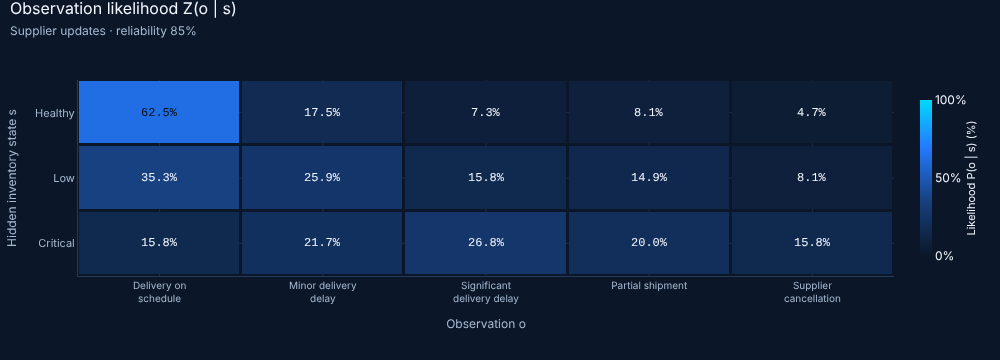

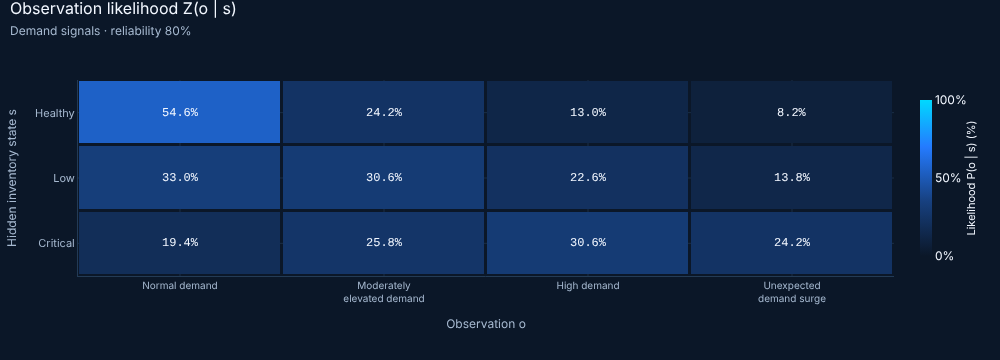

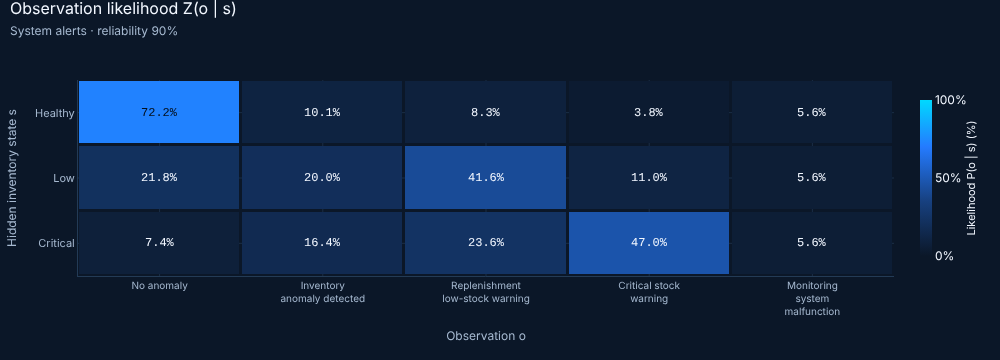

In [8]:
for key in CHANNEL_KEYS:
    show(viz.fig_observation_heatmap(observation_model.effective_matrix(key), observation_model.labels(key),
                                     CHANNELS[key]["label"], cfg.reliability[key]),
         f"04_observation_heatmap_{key}")

**Interpretation.** Each heatmap shows the *reliability-adjusted* likelihoods the agent actually uses. Three things are worth noticing.

1. **Diagnostic strength differs by channel.** The sensor and system-alert channels have a strong diagonal (a critical warning is far more probable when stock is Critical), so they move the belief a lot. Supplier and demand signals are flatter: a delay is more probable when stock is low, but it also happens when stock is fine, so it is weaker evidence.
2. **Malfunction symbols carry no information.** "Sensor malfunction" and "Monitoring system malfunction" have the same probability in every state. Their likelihood ratio is 1, so Bayes' rule leaves the belief unchanged.
3. **Association, not causation.** A supplier delay does not *reveal* the stock level. The likelihood encodes that late deliveries and depleted stock tend to occur together.

### 4.6 Cost and reward: reconciling current-state and post-transition costs

The cost of one executed transition depends on where the system was, what was done and where it landed:

$$C(s, a, s') = \underbrace{c_{\text{action}}(a)}_{\text{direct cost}} + \underbrace{c_{\text{current}}(s, a)}_{\text{depends on the CURRENT state}} + \underbrace{c_{\text{post}}(s')}_{\text{depends on the state the system LANDS in}}, \qquad R(s, a, s') = -C(s, a, s').$$

| Component | What it represents (synthetic assumption) |
|---|---|
| $c_{\text{action}}(a)$ | Standard ordering cost, expediting premium, production / reallocation cost |
| $c_{\text{current}}(s, a)$ | Surplus holding, wasted premium or needless disruption from intervening when stock is *already* Healthy |
| $c_{\text{post}}(s')$ | Inventory holding cost if Healthy, service degradation if Low, stock-out penalty and customer-service damage if Critical |

Taking the expectation under the belief gives the quantity the policy minimises (**derivation**):

$$Q(b, a) = \sum_{s} b(s) \sum_{s'} T(s' \mid s, a)\, C(s, a, s') = c_{\text{action}}(a) + \sum_s b(s)\, c_{\text{current}}(s, a) + \sum_{s'} b^-_a(s')\, c_{\text{post}}(s'),$$

where $b^-_a(s') = \sum_s T(s' \mid s, a)\, b(s)$ is the belief predicted after action $a$. The formula in the assignment brief, $Q(b,a) = C_{\text{action}}(a) + \sum_s b^-_a(s)\,C_{\text{state}}(s,a)$, is the special case $c_{\text{current}} = 0$. Section 7 checks numerically that the two forms above are identical.

### 4.7 Discount factor $\gamma$

$\gamma = 0.95$ completes the tuple. The primary SENTINEL policy looks one period ahead, which corresponds to $\gamma = 0$ in the belief-MDP Bellman backup. $\gamma$ is used only by the optional QMDP comparison in Section 9.

In [9]:
cost_tables = {
    f"Direct action cost c_action(a) ({COST_UNIT})": pd.DataFrame([cfg.action_cost], columns=ACTIONS, index=["cost"]),
    f"Current-state cost c_current(s, a) ({COST_UNIT})": pd.DataFrame(cfg.current_state_cost, columns=ACTIONS,
                                                                   index=[f"currently {s}" for s in STATES]),
    f"Post-transition cost c_post(s') ({COST_UNIT})": pd.DataFrame([cfg.post_state_cost],
                                                                  columns=[f"lands in {s}" for s in STATES], index=["cost"]),
}
for title, frame in cost_tables.items():
    print(title)
    display(frame.style.format("{:.1f}"))

assert check_inventory_bands() == [], check_inventory_bands()     # bands partition [0, 1,000] without gaps or overlaps
profile = service_profile(cfg)
physical = pd.DataFrame({
    "State": STATES,
    "Snapshot band (units, hidden)": [inventory_band_label(i) for i in range(len(STATES))],
    "Model-implied P(stock-out in the period)": profile["stockout_probability"],
    "Model-implied expected fill rate": profile["fill_rate"],
})
print("Synthetic state-conditioned unit proxies (simulator only) and the service profile they imply")
display(physical.style.hide(axis="index").format({"Model-implied P(stock-out in the period)": "{:.1%}",
                                                  "Model-implied expected fill rate": "{:.1%}"}))
print(f"Discount factor gamma = {cfg.discount}")

Direct action cost c_action(a) (SCU)


,Continue Monitoring,Standard Reorder,Expedite Supplier Delivery,Adjust Production / Reallocate Stock
cost,0.0,15.0,40.0,22.0


Current-state cost c_current(s, a) (SCU)


,Continue Monitoring,Standard Reorder,Expedite Supplier Delivery,Adjust Production / Reallocate Stock
currently Healthy,0.0,6.0,10.0,5.0
currently Low,0.0,0.0,0.0,0.0
currently Critical,0.0,0.0,0.0,0.0


Post-transition cost c_post(s') (SCU)


,lands in Healthy,lands in Low,lands in Critical
cost,4.0,20.0,150.0


Synthetic state-conditioned unit proxies (simulator only) and the service profile they imply


State,"Snapshot band (units, hidden)",Model-implied P(stock-out in the period),Model-implied expected fill rate
Healthy,"[600, 1,000]",0.0%,100.0%
Low,"[250, 600)",9.8%,98.4%
Critical,"[0, 250)",93.1%,45.4%


Discount factor gamma = 0.95


**Interpretation.** The stock-out penalty (landing in Critical) is by far the largest cost, which is what makes probability mass on Critical expensive. The service profile is computed by numerical integration over the uniform within-band snapshot and the demand distribution: with these assumptions a Critical period is short of stock most of the time and serves less than half of demand, a Low period occasionally runs short during demand surges, and a Healthy period never does. The agent may use this profile because it is knowledge of the *model*; it never sees any snapshot. Because snapshots are drawn independently each period, these are per-period, per-state figures, not the result of stock carried over from earlier periods.

## 5. Python environment and data generation

### 5.1 Environment

The libraries were imported in the set-up cell above: **NumPy** for probability arithmetic, **pandas** for tables, **SciPy** for the normal distribution and confidence intervals, and **Plotly** for charts. The project's own modules in `src/` hold every piece of mathematics, so this notebook calls and explains them instead of re-implementing them; the dashboard imports the same modules.

### 5.2 A reproducible synthetic dataset

The simulator generates a 120-period event history with a fixed seed. In each period, the hidden state transitions according to the executed action, each of the four channels emits one observation from its reliability-adjusted likelihood, and the simulator draws a state-conditioned inventory snapshot and an independent demand for evaluation. The behaviour policy is SENTINEL's own belief agent, so the data show a system that is being managed.

Random numbers come from separate fixed-length streams, so two policies run with the same seed face the same underlying randomness (*common random numbers*), which makes later comparisons fair.

In [10]:
agent_models = AgentModels.from_config(cfg)
behaviour_policy = BeliefMyopicPolicy(agent_models.transition, agent_models.cost)
events = generate_event_dataset(cfg, behaviour_policy, horizon=120, seed=SEED)

data_path = ROOT / "data" / "sample_events.csv"
data_path.parent.mkdir(exist_ok=True)
events.to_csv(data_path, index=False)

observed_cols = [c for c in events.columns if not c.startswith("eval_")]
hidden_cols = [c for c in events.columns if c.startswith("eval_")]
print(f"Saved {len(events)} periods to data/{data_path.name}")
print(f"Observable by the agent ({len(observed_cols)} columns): {observed_cols}")
print(f"Hidden evaluation labels ({len(hidden_cols)} columns): {hidden_cols}")
display(events.head(8))

Saved 120 periods to data/sample_events.csv
Observable by the agent (14 columns): ['period', 'date', 'sensor_observation', 'sensor_assumed_reliability', 'supplier_observation', 'supplier_assumed_reliability', 'demand_observation', 'demand_assumed_reliability', 'system_observation', 'system_assumed_reliability', 'executed_action', 'belief_healthy', 'belief_low', 'belief_critical']
Hidden evaluation labels (6 columns): ['eval_hidden_state', 'eval_inventory_units', 'eval_demand_units', 'eval_fill_rate', 'eval_stockout', 'eval_realised_cost_scu']


,period,date,sensor_observation,sensor_assumed_reliability,supplier_observation,supplier_assumed_reliability,demand_observation,demand_assumed_reliability,system_observation,system_assumed_reliability,executed_action,belief_healthy,belief_low,belief_critical,eval_hidden_state,eval_inventory_units,eval_demand_units,eval_fill_rate,eval_stockout,eval_realised_cost_scu
0,0,2026-11-11,(none - initial period),0.9,(none - initial period),0.85,(none - initial period),0.8,(none - initial period),0.9,Continue Monitoring,0.6000,0.3000,0.1000,Critical,190.9,361.1,0.5289,True,150.0
1,1,2026-11-12,Low inventory reading,0.9,Significant delivery delay,0.85,High demand,0.8,Critical stock warning,0.9,Expedite Supplier Delivery,0.0113,0.3328,0.6559,Critical,178.2,311.2,0.5728,True,44.0
2,2,2026-11-13,Low inventory reading,0.9,Partial shipment,0.85,Normal demand,0.8,Inventory anomaly detected,0.9,Standard Reorder,0.1727,0.7895,0.0378,Healthy,685.4,195.0,1.0000,False,25.0
3,3,2026-11-14,Normal inventory reading,0.9,Delivery on schedule,0.85,Moderately elevated demand,0.8,No anomaly,0.9,Continue Monitoring,0.9709,0.0288,0.0003,Healthy,746.6,207.2,1.0000,False,4.0
4,4,2026-11-15,Critical inventory warning,0.9,Minor delivery delay,0.85,Moderately elevated demand,0.8,No anomaly,0.9,Continue Monitoring,0.7617,0.1959,0.0424,Healthy,642.7,282.0,1.0000,False,20.0
5,5,2026-11-16,Low inventory reading,0.9,Supplier cancellation,0.85,Normal demand,0.8,Critical stock warning,0.9,Adjust Production / Reallocate Stock,0.1004,0.5291,0.3704,Low,370.1,167.3,1.0000,False,26.0
6,6,2026-11-17,Normal inventory reading,0.9,Delivery on schedule,0.85,Normal demand,0.8,Critical stock warning,0.9,Continue Monitoring,0.8465,0.1343,0.0192,Healthy,808.9,157.5,1.0000,False,4.0
7,7,2026-11-18,Normal inventory reading,0.9,Delivery on schedule,0.85,Normal demand,0.8,No anomaly,0.9,Continue Monitoring,0.9937,0.0062,0.0001,Healthy,603.3,200.9,1.0000,False,4.0


**Dataset structure.**

- `period`, `date`: the simulated clock (one period = one operating day).
- `*_observation`: what each channel reported. `*_assumed_reliability` is the reliability the agent assumes for that channel.
- `executed_action`: the action that was actually executed in that period.
- `belief_*`: the agent's belief when it chose the action.
- `eval_*`: **hidden evaluation labels**: the true state, the synthetic state-conditioned inventory snapshot (`eval_inventory_units`, drawn within the state's band, not rolled forward), demand, fill rate, stock-out flag and realised cost. These columns exist only so the simulation can be scored. They are never inputs to the belief update or the decision.

In [11]:
state_share = events["eval_hidden_state"].value_counts(normalize=True).reindex(STATES).rename("share of periods")
action_share = events["executed_action"].value_counts(normalize=True).reindex(ACTIONS).fillna(0).rename("share of periods")
sensor_vs_truth = pd.crosstab(events["eval_hidden_state"], events["sensor_observation"], normalize="index").reindex(STATES)

print("Hidden state frequency (evaluation label)")
display(pct(state_share.to_frame()))
print("Executed action frequency")
display(pct(action_share.to_frame()))
print("Empirical P(sensor observation | hidden state) in this sample (compare with the sensor heatmap)")
display(pct(sensor_vs_truth))

Hidden state frequency (evaluation label)


,share of periods
eval_hidden_state,
Healthy,71.7%
Low,15.8%
Critical,12.5%


Executed action frequency


,share of periods
executed_action,
Continue Monitoring,71.7%
Standard Reorder,14.2%
Expedite Supplier Delivery,5.8%
Adjust Production / Reallocate Stock,8.3%


Empirical P(sensor observation | hidden state) in this sample (compare with the sensor heatmap)


sensor_observation,(none - initial period),Critical inventory warning,Low inventory reading,Normal inventory reading,Sensor malfunction / unreliable reading
eval_hidden_state,,,,,
Healthy,0.0%,8.1%,14.0%,61.6%,16.3%
Low,0.0%,10.5%,78.9%,5.3%,5.3%
Critical,6.7%,40.0%,33.3%,6.7%,13.3%


**Interpretation.** The last table is an empirical check that observations are *evidence, not truth*: even in Healthy periods the sensor sometimes reports low or critical readings, and in Critical periods it sometimes reports normal ones. Within sampling error, the frequencies follow the reliability-adjusted likelihoods of Section 4.5, because that is the model the simulator draws from. The first period shows "(none – initial period)" because the first observations arrive only after the first executed action.

**Link to RDMU.** A dataset like this is what a real system would log, minus the `eval_` columns. The gap between the observable columns and the hidden ones is the partial-observability problem.

## 6. Implementation of the belief-state engine

### 6.1 The two-stage Bayes filter

**Stage 1 – prediction** (only when an action has been executed). The belief is pushed through the transition model of the executed action:

$$b^-(s') = \sum_{s} T(s' \mid s, a)\, b(s).$$

**Stage 2 – correction** (with all observations of the period). The predicted belief is re-weighted by how well each state explains the evidence and renormalised:

$$b'(s') = \eta \left[\prod_{k} Z_k(o_k \mid s')\right] b^-(s'), \qquad \eta^{-1} = \sum_{s'} \left[\prod_{k} Z_k(o_k \mid s')\right] b^-(s') = P(o_1, \dots, o_K \mid b, a).$$

Prediction answers *"where could inventory have moved?"*; correction answers *"which states explain what we just saw?"*. The normalising constant $\eta^{-1}$ is the probability the model assigned to the evidence, so a small value means the evidence was surprising. This is the exact belief update of Kaelbling et al. (1998), written as the discrete state filter of Kochenderfer et al. (2022).

**Conditional independence (explicit assumption).** The product over channels assumes that, *given the hidden state*, the channels err independently. This is the naive-Bayes assumption. Section 6.5 shows what happens when it is violated.

### 6.2 Worked example by hand

Start from $b_0 = [0.60, 0.30, 0.10]$. The operator executes **Continue Monitoring**, then the sensor reports a **low inventory reading** (sensor reliability 90%). Every intermediate number is shown.

In [12]:
T_monitor = transition_model.matrix("monitor")
z_low = observation_model.likelihood_vector("sensor", "Low inventory reading")     # reliability-adjusted

# Stage 1: prediction, written out term by term
contributions = b0[:, None] * T_monitor                 # b(s) * T(s'|s,a): row = from s, column = to s'
predicted_manual = contributions.sum(axis=0)

# Stage 2: correction
unnormalised = z_low * predicted_manual
evidence_probability = unnormalised.sum()               # eta^-1
posterior_manual = unnormalised / evidence_probability

worked = pd.DataFrame({
    "Prior b(s)": b0,
    "Predicted b⁻(s′)": predicted_manual,
    "Likelihood Z_r(low reading | s′)": z_low,
    "Product Z · b⁻": unnormalised,
    "Posterior b′(s′)": posterior_manual,
}, index=STATES)
print("Stage 1 contributions b(s) · T(s′ | s, monitor)  (rows: from s, columns: to s′)")
display(pd.DataFrame(contributions, index=[f"from {s}" for s in STATES], columns=[f"to {s}" for s in STATES])
        .style.format("{:.4f}"))
print(f"eta^-1 = P(low reading | b0, monitor) = {evidence_probability:.4f}   ->   eta = {1 / evidence_probability:.4f}")
display(worked.style.format("{:.4f}"))

# The shared engine must reproduce the hand calculation exactly
update = bayes_update(b0, T_monitor, [z_low])
assert np.allclose(update.predicted, predicted_manual) and np.allclose(update.posterior, posterior_manual)
assert abs(update.posterior.sum() - 1.0) < 1e-12
print("Engine output matches the hand calculation:", np.round(update.posterior, 4))

Stage 1 contributions b(s) · T(s′ | s, monitor)  (rows: from s, columns: to s′)


,to Healthy,to Low,to Critical
from Healthy,0.5100,0.0780,0.0120
from Low,0.0150,0.2100,0.0750
from Critical,0.0010,0.0090,0.0900


eta^-1 = P(low reading | b0, monitor) = 0.2970   ->   eta = 3.3667


,Prior b(s),Predicted b⁻(s′),Likelihood Z_r(low reading | s′),Product Z · b⁻,Posterior b′(s′)
Healthy,0.6000,0.5260,0.1330,0.0700,0.2355
Low,0.3000,0.2970,0.6370,0.1892,0.6369
Critical,0.1000,0.1770,0.2140,0.0379,0.1275


Engine output matches the hand calculation: [0.2355 0.6369 0.1275]


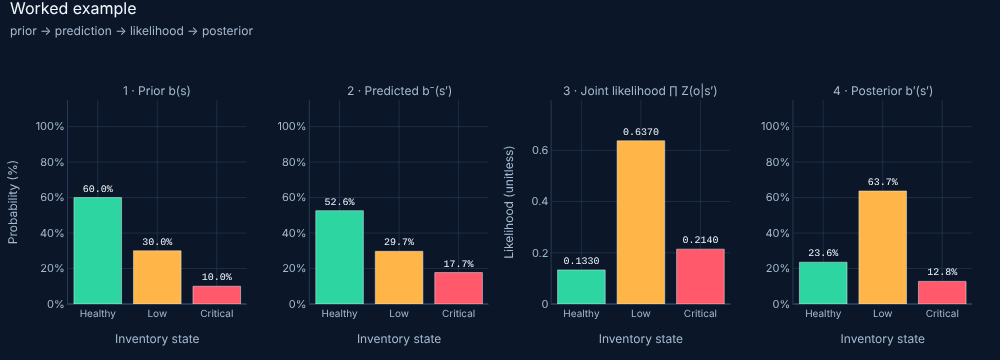

In [13]:
show(viz.fig_bayes_explorer(update.prior, update.predicted, update.joint_likelihood, update.posterior,
                            title="Worked example: prior → prediction → likelihood → posterior"),
     "05_bayes_worked_example")

**Interpretation.**

- **Prediction** alone already lowers P(Healthy) from 60.0% to 52.6% and raises P(Critical) from 10.0% to 17.7%. Nothing was observed; the model simply knows that a day of demand without replenishment tends to deplete stock.
- **Correction** then shifts mass to Low (to about 64%), because a low reading is almost five times as probable when stock is Low as when it is Healthy.
- P(Critical) *falls* from 17.7% to about 12.8%. The reading is "low", not "critical", and the Critical state explains a low reading much less well than the Low state does. The update follows the likelihoods, not the alarming sound of an alert.

### 6.3 Multiple observations: one prediction, one joint correction

When several alerts arrive in the same period, they are combined in a **single** correction after a **single** prediction. Applying the full predict-then-correct cycle once per alert would be a bug: it would apply the transition model several times, as if several days had passed. Under conditional independence, the joint correction equals correcting with each observation in turn, in any order.

In [14]:
evidence = {
    "Sensor: Low inventory reading": observation_model.likelihood_vector("sensor", "Low inventory reading"),
    "Supplier: Significant delivery delay": observation_model.likelihood_vector("supplier", "Significant delivery delay"),
    "Demand: High demand": observation_model.likelihood_vector("demand", "High demand"),
}
vectors = list(evidence.values())
predicted = predict(b0, T_monitor)                                  # ONE prediction

joint = correct(predicted, vectors)                                 # ONE joint correction
sequential = correct_sequential(predicted, vectors)                 # same evidence, one at a time
reverse = correct_sequential(predicted, vectors[::-1])              # ... in reverse order

steps = pd.DataFrame([predicted] + sequential, columns=STATES,
                     index=["Predicted b⁻ (no evidence yet)"] + [f"+ {name}" for name in evidence])
display(pct(steps, digits=2))
print("Joint posterior      :", np.round(joint.posterior, 6))
print("Sequential posterior :", np.round(sequential[-1], 6))
print("Reverse-order result :", np.round(reverse[-1], 6))
assert np.allclose(joint.posterior, sequential[-1], atol=1e-12) and np.allclose(joint.posterior, reverse[-1], atol=1e-12)

# The bug this design avoids: predicting before EVERY observation
wrong = b0.copy()
for v in vectors:
    wrong = bayes_update(wrong, T_monitor, [v]).posterior
print("WRONG (prediction applied three times):", np.round(wrong, 6),
      "-> differs by", np.round(np.abs(wrong - joint.posterior).max(), 4))

,Healthy,Low,Critical
Predicted b⁻ (no evidence yet),52.60%,29.70%,17.70%
+ Sensor: Low inventory reading,23.55%,63.69%,12.75%
+ Supplier: Significant delivery delay,11.27%,66.19%,22.55%
+ Demand: High demand,6.28%,64.14%,29.58%


Joint posterior      : [0.062797 0.641361 0.295843]
Sequential posterior : [0.062797 0.641361 0.295843]
Reverse-order result : [0.062797 0.641361 0.295843]
WRONG (prediction applied three times): [0.057087 0.328155 0.614758] -> differs by 0.3189


**Interpretation.** The joint, sequential and reverse-order results agree to machine precision, which confirms that the order in which simultaneous alerts are processed does not matter. The last line shows that inserting a prediction step before every alert gives a visibly different, incorrect belief: it overstates depletion because it treats three alerts as three days.

### 6.4 Reliability adjustment

How much should one alert move the belief? It depends on how much the channel can be trusted. The same sensor reading, **"critical inventory warning"**, is applied to $b_0$ at different reliabilities.

,Z_r(o | Healthy),Z_r(o | Low),Z_r(o | Critical),P(Healthy),P(Low),P(Critical)
Sensor reliability,,,,,,
0.000000,25.0%,25.0%,25.0%,60.0%,30.0%,10.0%
0.250000,19.5%,21.8%,36.2%,53.5%,29.9%,16.6%
0.500000,14.0%,18.5%,47.5%,44.9%,29.7%,25.4%
0.750000,8.5%,15.2%,58.7%,32.8%,29.4%,37.8%
0.900000,5.2%,13.3%,65.5%,22.8%,29.2%,48.0%
1.000000,3.0%,12.0%,70.0%,14.5%,29.0%,56.5%


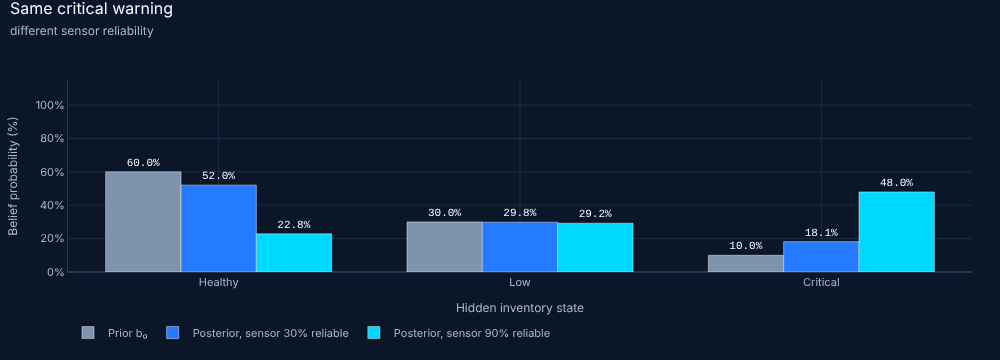

In [15]:
rows = []
for r in (0.0, 0.25, 0.5, 0.75, 0.9, 1.0):
    z = observation_model.likelihood_vector("sensor", "Critical inventory warning", reliability=r)
    post = correct(b0, [z]).posterior
    rows.append({"Sensor reliability": r, "Z_r(o | Healthy)": z[0], "Z_r(o | Low)": z[1], "Z_r(o | Critical)": z[2],
                 "P(Healthy)": post[0], "P(Low)": post[1], "P(Critical)": post[2]})
reliability_table = pd.DataFrame(rows).set_index("Sensor reliability")
display(pct(reliability_table))

show(viz.fig_before_after({
    "Prior b₀": b0,
    "Posterior, sensor 30% reliable": correct(b0, [observation_model.likelihood_vector("sensor", 2, 0.30)]).posterior,
    "Posterior, sensor 90% reliable": correct(b0, [observation_model.likelihood_vector("sensor", 2, 0.90)]).posterior,
}, "Same critical warning, different sensor reliability"), "06_reliability_effect")

**Interpretation.** At 0% reliability, the three likelihoods are equal and the posterior equals the prior: the alert is pure noise and is correctly ignored. As reliability rises, the likelihoods separate and the same alert moves more probability to Critical. The agent's response to an alarm is therefore graded by trust in the alarm's source. This is the key difference from the record-trusting heuristic evaluated in Section 9, which reacts to every reading as if it were certain.

### 6.5 Correlated alerts and double counting

The conditional-independence assumption fails when two alerts are really the same piece of evidence, for example a system alert that is generated *from* the sensor reading, or one warning relayed three times. Treating the copies as independent multiplies the same likelihood ratio again and again. **Published finding:** models that make unrealistic independence assumptions push probabilities towards 0 and 1 (Niculescu-Mizil & Caruana, 2005), and probability estimates are optimal only if the independence assumption holds (Domingos & Pazzani, 1997).

The demonstration: one "critical stock warning" arrives and is then relayed twice more.

,Healthy,Low,Critical,Belief concentration
Counted once (correct: one piece of evidence),22.2%,32.1%,45.7%,0.04
Counted twice as independent,3.3%,13.7%,83.1%,0.51
Counted three times as independent,0.3%,3.7%,96.0%,0.84


Guard ON  -> P(Critical) = 45.7% | last status: duplicate ignored
Guard OFF -> P(Critical) = 96.0% | last status: applied as independent (guard off)


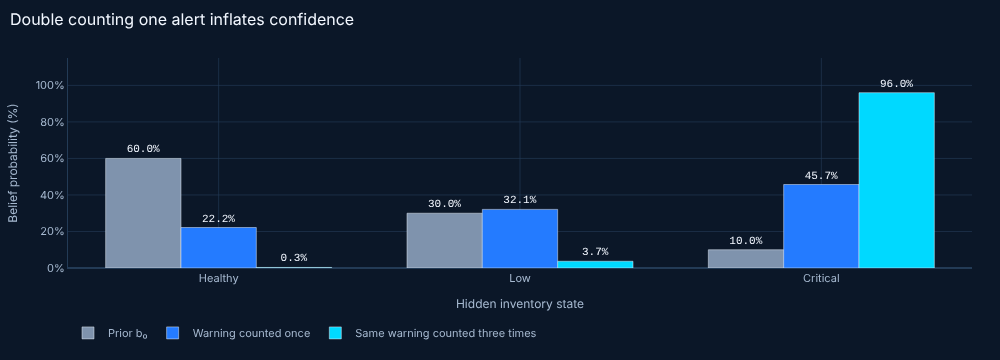

In [16]:
z_crit = observation_model.likelihood_vector("system", "Critical stock warning")
double_count = pd.DataFrame(
    [correct(b0, [z_crit] * n).posterior for n in (1, 2, 3)], columns=STATES,
    index=["Counted once (correct: one piece of evidence)", "Counted twice as independent",
           "Counted three times as independent"])
double_count["Belief concentration"] = [belief_concentration(row) for row in double_count[list(STATES)].to_numpy()]
display(double_count.style.format({**{s: "{:.1%}" for s in STATES}, "Belief concentration": "{:.2f}"}))

# The engine's duplicate guard: one reading per channel per period
guarded, unguarded = SentinelEngine(cfg), SentinelEngine(cfg, deduplicate=False)
for engine in (guarded, unguarded):
    for _ in range(3):
        result = engine.inject_alert("system", "Critical stock warning")
print("Guard ON  -> P(Critical) =", f"{guarded.belief[2]:.1%}", "| last status:", guarded.event_log[-1]["Status"])
print("Guard OFF -> P(Critical) =", f"{unguarded.belief[2]:.1%}", "| last status:", unguarded.event_log[-1]["Status"])

show(viz.fig_before_after({"Prior b₀": b0, "Warning counted once": double_count.iloc[0][list(STATES)].to_numpy(float),
                           "Same warning counted three times": double_count.iloc[2][list(STATES)].to_numpy(float)},
                          "Double counting one alert inflates confidence"), "07_double_counting")

**Interpretation.** One warning is strong evidence. Counting the *same* warning three times produces near-certainty that stock is Critical, although no new information arrived after the first report. The belief has become overconfident, and an overconfident belief triggers expensive actions too readily.

**Implementation decision.** The engine accepts at most one observation per channel per period: an identical repeat is ignored and a revised report replaces the earlier one. The dashboard exposes this as a "duplicate-event prevention" switch so that the effect above can be reproduced live. The guard handles exact repeats within a channel. It cannot detect correlation *between* channels, which Section 9.5 quantifies with a model-mismatch experiment.

### 6.6 Invalid observations and numerical stability

The engine validates its inputs and never divides by zero.

- Beliefs, likelihoods and reliabilities outside $[0, 1]$, unknown channels and unknown observations raise a clear error.
- Likelihood matrices are floored at $\varepsilon = 10^{-9}$ and renormalised, so the model never asserts that an observation is impossible.
- The correction is computed in **log-space** with the log-sum-exp trick, so the product of many small likelihoods cannot underflow.
- If evidence still has zero probability under the model, the predicted belief is returned unchanged and the result is flagged as impossible evidence.

In [17]:
# 1. invalid inputs are rejected with meaningful messages
probe = SentinelEngine(cfg)
for label, call in {
    "unknown channel": lambda: probe.inject_alert("satellite", "Normal inventory reading"),
    "unknown observation": lambda: probe.inject_alert("sensor", "Stock looks fine"),
    "reliability > 1": lambda: probe.inject_alert("sensor", "Normal inventory reading", reliability=1.7),
    "belief not summing to 1": lambda: validate_belief([0.7, 0.3, 0.2]),
}.items():
    try:
        call()
    except ValueError as error:
        print(f"{label:>24s} -> rejected: {error}")
assert np.allclose(probe.belief, b0) and probe.alerts_processed == 0        # nothing was changed

# 2. log-space normalisation: 400 tiny likelihoods whose naive product underflows to exactly 0
tiny = [np.array([1e-9, 3e-9, 2e-9])] * 400
print("\nNaive product of the Low-state likelihoods:", np.prod([v[1] for v in tiny]))
stable = correct(b0, tiny)
print("Log-space posterior:", stable.posterior, "| sums to", stable.posterior.sum())

# 3. impossible evidence: the only state that explains it has zero prior probability
impossible = correct([0.5, 0.5, 0.0], [np.array([0.0, 0.0, 0.9])])
print("\nImpossible evidence flagged:", impossible.impossible, "| belief kept:", impossible.posterior)

         unknown channel -> rejected: Unknown observation channel: 'satellite'. Valid: ('sensor', 'supplier', 'demand', 'system').
     unknown observation -> rejected: Unknown observation 'Stock looks fine' for channel 'sensor'.
         reliability > 1 -> rejected: Observation reliability must lie between 0 and 1.
 belief not summing to 1 -> rejected: belief must sum to 1; it sums to 1.20000000.

Naive product of the Low-state likelihoods: 0.0
Log-space posterior: [2.83483710e-191 1.00000000e+000 1.22004296e-071] | sums to 1.0

Impossible evidence flagged: True | belief kept: [0.5 0.5 0. ]


**Interpretation.** Invalid inputs are refused without altering the session, extreme evidence is handled without numerical underflow, and evidence the model cannot explain is flagged instead of producing `NaN`. These protections matter in an interactive dashboard, where a user can enter anything.

**Link to RDMU.** Sections 6.1–6.6 are the "reasoning" half of the course title: a principled, auditable way to turn imperfect evidence into calibrated probabilities.

## 7. Intelligent decision policy

### 7.1 The rule

For the current belief $b$, the agent evaluates **all four** actions with the expected one-step cost of Section 4.6 and recommends the cheapest:

$$Q(b, a) = c_{\text{action}}(a) + \sum_s b(s)\, c_{\text{current}}(s, a) + \sum_{s'} b^-_a(s')\, c_{\text{post}}(s'), \qquad a^* = \arg\min_a Q(b, a), \qquad R(b, a) = -Q(b, a).$$

**What this policy is and is not.** It is the exact optimum for a *one-period* problem under the stated model, and it is fully explainable because each $Q$ value splits into three readable parts. It is **not** an optimal infinite-horizon POMDP policy: it ignores costs beyond the next period and, like QMDP, it places no value on gathering information (Littman et al., 1995; Ross et al., 2008). No action is selected by a hard-coded threshold; the recommendation is always the arg-min computed by `evaluate_actions`.

### 7.2 Expected-cost comparison at the initial belief

Action,Direct action cost (SCU),Expected current-state cost (SCU),Expected post-transition cost (SCU),"Expected total cost Q(b,a) (SCU)",Predicted P(Critical) next period,Rank,Recommended
Continue Monitoring,0.00,0.00,34.59,34.59,17.7%,1,yes
Standard Reorder,15.00,3.60,17.53,36.13,7.0%,2,
Expedite Supplier Delivery,40.00,6.00,8.82,54.82,2.0%,4,
Adjust Production / Reallocate Stock,22.00,3.00,14.45,39.45,4.9%,3,


Current belief         : Healthy 60%, Low 30%, Critical 10%
Lowest expected cost   : Continue Monitoring  ->  34.59 SCU
Second-best alternative: Standard Reorder  ->  36.13 SCU
Difference             : 1.54 SCU (4.4% of the best cost)
Expected reward R(b, a*) = -Q = -34.59 SCU

By hand, Q(b0, monitor) = 0.526*4 + 0.297*20 + 0.177*150 = 34.594


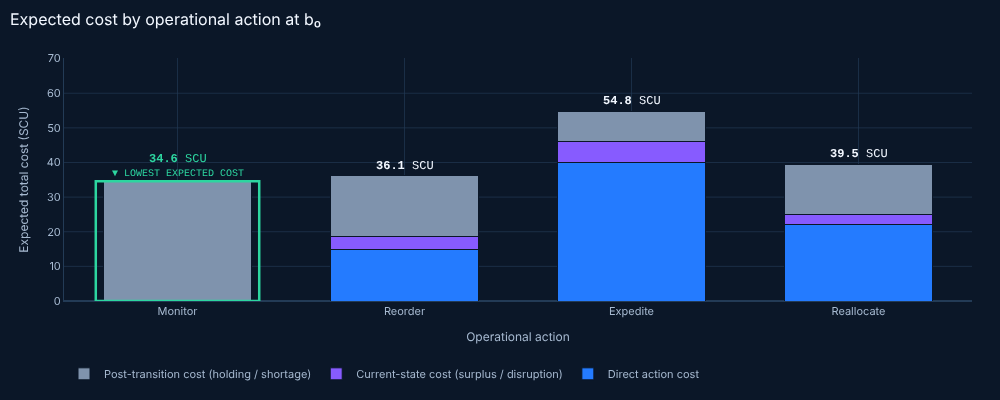

In [18]:
decision = evaluate_actions(b0, transition_model, cost_model)
comparison = decision.as_frame()
display(comparison.style.hide(axis="index").format({
    c: "{:.2f}" for c in comparison.columns if COST_UNIT in c} | {"Predicted P(Critical) next period": "{:.1%}"}))

best, second = decision.action, decision.runner_up
print(f"Current belief         : Healthy {b0[0]:.0%}, Low {b0[1]:.0%}, Critical {b0[2]:.0%}")
print(f"Lowest expected cost   : {ACTIONS[best]}  ->  {decision.q_values[best]:.2f} {COST_UNIT}")
print(f"Second-best alternative: {ACTIONS[second]}  ->  {decision.q_values[second]:.2f} {COST_UNIT}")
print(f"Difference             : {decision.margin:.2f} {COST_UNIT} ({decision.margin_pct:.1f}% of the best cost)")
print(f"Expected reward R(b, a*) = -Q = {decision.expected_reward:.2f} {COST_UNIT}")

# Hand check of one entry: Continue Monitoring
b_minus = b0 @ transition_model.matrix("monitor")
q_monitor_by_hand = 0.0 + 0.0 + b_minus @ cfg.post_state_cost
print(f"\nBy hand, Q(b0, monitor) = {b_minus[0]:.3f}*{cfg.post_state_cost[0]:.0f} + {b_minus[1]:.3f}*"
      f"{cfg.post_state_cost[1]:.0f} + {b_minus[2]:.3f}*{cfg.post_state_cost[2]:.0f} = {q_monitor_by_hand:.3f}")
assert np.isclose(q_monitor_by_hand, decision.q_values[0])

show(viz.fig_action_costs(decision, "Expected cost by operational action at b₀"), "08_action_costs_initial")

In [19]:
explanation = explain_decision(decision, b0, [], None)
display(Markdown(f"**{explanation['headline']}**\n\n> {explanation['paragraph']}"))

**NOVA RECOMMENDATION: CONTINUE MONITORING**

> No new evidence has been received this period, so the belief is the model's prediction: Healthy 60.0%, Low 30.0%, Critical 10.0%. Continue Monitoring has the lowest expected total cost, 34.6 SCU, against 36.1 SCU for Standard Reorder (margin 1.5 SCU, 4.4%). Intervening with Standard Reorder would cut the expected holding-and-shortage cost by only 17.1 SCU while adding 18.6 SCU of ordering and surplus cost, so waiting for more evidence is cheaper under the current belief.

**Interpretation.** At the infographic's starting belief, the agent recommends **Continue Monitoring**, but only narrowly: a standard reorder costs just a little more in expectation. Monitoring has no direct cost yet carries the largest shortage exposure (the tall grey segment), while each intervention buys down that exposure at a price. With a 60% chance that stock is already healthy, the purchase is not quite worth it. The small margin is informative in its own right: it says the decision is close, so even modest adverse evidence should tip it. Section 8 confirms this.

The explanation above is generated from the live numbers (belief, cost components, margin), so it changes whenever they do.

### 7.3 Numerical check of the Bellman-style expectation

The decomposed form used by the engine must equal the textbook double sum $\sum_s b(s) \sum_{s'} T(s' \mid s,a)\,C(s,a,s')$ for any belief. It must also equal the linear form $Q(b, \cdot) = b^\top M$ with $M[s,a] = \sum_{s'} T(s' \mid s,a)\,C(s,a,s')$.

In [20]:
rng = np.random.default_rng(SEED)
one_step_matrix = cost_model.one_step_cost_matrix(transition_model.tensor())     # M[s, a]
worst_gap = 0.0
for _ in range(2000):
    b = rng.dirichlet(np.ones(3))
    d = evaluate_actions(b, transition_model, cost_model)
    bellman = np.array([cost_model.expected_cost_bellman(b, a, transition_model.matrix(a)) for a in range(4)])
    worst_gap = max(worst_gap, np.abs(d.q_values - bellman).max(), np.abs(d.q_values - b @ one_step_matrix).max())
print(f"Largest disagreement over 2,000 random beliefs: {worst_gap:.2e} {COST_UNIT}")
assert worst_gap < 1e-10
print(f"\nOne-step cost matrix M[s, a] ({COST_UNIT}) = expected cost of action a if the state were known to be s")
display(pd.DataFrame(one_step_matrix, index=[f"true state {s}" for s in STATES], columns=ACTIONS).style.format("{:.2f}")
        .highlight_min(axis=1, props="font-weight: bold; color: #2DD6A0;"))

Largest disagreement over 2,000 random beliefs: 2.84e-14 SCU

One-step cost matrix M[s, a] (SCU) = expected cost of action a if the state were known to be s


,Continue Monitoring,Standard Reorder,Expedite Supplier Delivery,Adjust Production / Reallocate Stock
true state Healthy,9.00,27.42,55.29,33.90
true state Low,51.70,37.40,51.90,40.20
true state Critical,136.84,84.60,60.80,70.50


**Interpretation.** The three forms agree to rounding error, so the cost definitions are internally consistent. The matrix $M$ is also a compact summary of the policy's logic: read along a row to see what each action would cost *if the state were known*. The cheapest action is Continue Monitoring when stock is Healthy, Standard Reorder when it is Low and Expedite when it is Critical. Under uncertainty, the agent blends these rows with its belief weights.

### 7.4 The policy map: thresholds emerge from costs

Because $Q(b, a)$ is **linear** in $b$, the region of beliefs where a given action is optimal is convex. The chart below evaluates the arg-min over the whole belief simplex.

,Share of the belief simplex where the action is optimal
action_name,
Continue Monitoring,15.7%
Standard Reorder,27.6%
Expedite Supplier Delivery,15.0%
Adjust Production / Reallocate Stock,41.7%


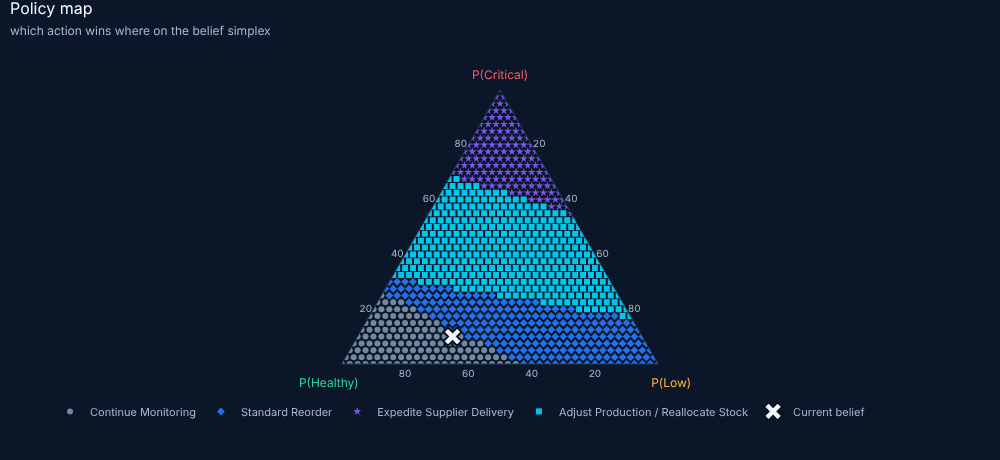

In [21]:
grid = policy_region_grid(transition_model, cost_model, resolution=40)
region_share = grid["action_name"].value_counts(normalize=True).reindex(ACTIONS).fillna(0)
display(pct(region_share.rename("Share of the belief simplex where the action is optimal").to_frame()))
show(viz.fig_policy_map(grid, b0), "09_policy_map")

**Interpretation.** Each corner of the triangle is certainty about one state; the white × is $b_0$. Near the Healthy corner the agent monitors. Moving towards Low, it reorders; with a mixed Low/Critical picture it prefers internal reallocation, which is cheaper than expediting and recovers faster than a standard order; only when Critical dominates does it pay the expedite premium. The infographic sketches fixed rules of the form "if P(Critical) > 20% then …". Here the boundaries are **outputs** of the cost model. Change a cost and the regions move, which a hard-coded threshold cannot do (Section 9.6 shows the consequence).

### 7.5 The same alert can lead to different actions

An alert does not map to an action. It moves the belief, and the action depends on where the belief ends up. The same supplier message, **"significant delivery delay"**, is applied to three different priors.

In [22]:
priors = {"Confident that stock is healthy": [0.90, 0.08, 0.02],
          "Infographic prior b₀": [0.60, 0.30, 0.10],
          "Already worried": [0.40, 0.45, 0.15]}
z_delay = observation_model.likelihood_vector("supplier", "Significant delivery delay")
rows = []
for name, prior in priors.items():
    prior = np.array(prior)
    posterior = correct(prior, [z_delay]).posterior
    before, after = evaluate_actions(prior, transition_model, cost_model), evaluate_actions(posterior, transition_model, cost_model)
    rows.append({"Prior situation": name, "Prior (H / L / C)": format_belief(prior),
                 "Recommended before": ACTIONS[before.action], "Posterior (H / L / C)": format_belief(posterior),
                 "Recommended after": ACTIONS[after.action],
                 f"Margin after ({COST_UNIT})": round(after.margin, 2)})
display(pd.DataFrame(rows).style.hide(axis="index"))

Prior situation,Prior (H / L / C),Recommended before,Posterior (H / L / C),Recommended after,Margin after (SCU)
Confident that stock is healthy,90.0% / 8.0% / 2.0%,Continue Monitoring,78.4% / 15.1% / 6.4%,Continue Monitoring,8.910000
Infographic prior b₀,60.0% / 30.0% / 10.0%,Continue Monitoring,37.0% / 40.2% / 22.8%,Standard Reorder,0.310000
Already worried,40.0% / 45.0% / 15.0%,Standard Reorder,20.7% / 50.6% / 28.7%,Adjust Production / Reallocate Stock,1.290000


**Interpretation.** One identical alert produces three different outcomes because the priors differ. Where the agent was confident, the delay is absorbed and monitoring continues. From $b_0$, the same delay is enough to tip the close decision towards ordering. Where the agent was already worried and recommending a reorder, the same message pushes it to a stronger intervention. This is the central idea of the lab: **alerts change beliefs, and beliefs (together with costs) determine decisions.**

**Link to RDMU.** This is expected-utility decision-making under uncertainty: probabilities come from Section 6, consequences from the cost model, and the decision is the action with the best expected consequence.

## 8. Dynamic alert simulation

Eight scripted scenarios (A–H) are replayed through the **shared engine**, exactly as the dashboard's preset loader does. Scenarios are deterministic: every alert is scripted and nothing is sampled, so the notebook and the dashboard produce identical numbers.

For each scenario, the table lists every event with the belief after it and the standing recommendation. The chart compares the belief before and after the scenario, and the quoted paragraph is the engine's own dynamically generated explanation of its final recommendation.

Event kinds: **alert** = an observation was injected and the belief corrected; **predict** = an action was executed and the belief was pushed through that action's transition model; **init** = the starting belief.

**Scenario A: Normal Inventory Operations.** All four channels report nominal conditions over three periods. Belief should concentrate on Healthy and the agent should keep monitoring.

Event,Kind,Period,P(Healthy),P(Low),P(Critical),Recommended action,Expected cost (SCU)
Session initialised with the prior belief,init,0,60.0%,30.0%,10.0%,Continue Monitoring,34.59
Sensor readings: Normal inventory reading,alert,0,89.2%,9.6%,1.2%,Continue Monitoring,14.65
Supplier updates: Delivery on schedule,alert,0,94.0%,5.7%,0.3%,Continue Monitoring,11.85
Demand signals: Normal demand,alert,0,96.4%,3.5%,0.1%,Continue Monitoring,10.66
System alerts: No anomaly,alert,0,98.9%,1.1%,0.0%,Continue Monitoring,9.48
Executed Continue Monitoring; belief predicted for period 1,predict,1,84.1%,13.6%,2.3%,Continue Monitoring,17.71
Sensor readings: Normal inventory reading,alert,1,96.4%,3.4%,0.2%,Continue Monitoring,10.70
Demand signals: Normal demand,alert,1,97.9%,2.1%,0.1%,Continue Monitoring,9.98
Executed Continue Monitoring; belief predicted for period 2,predict,2,83.3%,14.2%,2.5%,Continue Monitoring,18.30
Sensor readings: Normal inventory reading,alert,2,96.2%,3.5%,0.2%,Continue Monitoring,10.81


Belief before: **60.0% / 30.0% / 10.0%** → after: **97.9% / 2.0% / 0.1%** (Healthy / Low / Critical). Recommendation did not change: **Continue Monitoring → Continue Monitoring**; it switched 0 time(s) along the way.

> P(Healthy) rose from 83.3% to 97.9% (+14.6 pts) after Sensor readings: “Normal inventory reading” (90% reliable); Supplier updates: “Delivery on schedule” (85% reliable). Continue Monitoring has the lowest expected total cost, 9.9 SCU, against 27.7 SCU for Standard Reorder (margin 17.7 SCU, 178.2%). Intervening with Standard Reorder would cut the expected holding-and-shortage cost by only 3.2 SCU while adding 20.9 SCU of ordering and surplus cost, so waiting for more evidence is cheaper under the current belief.

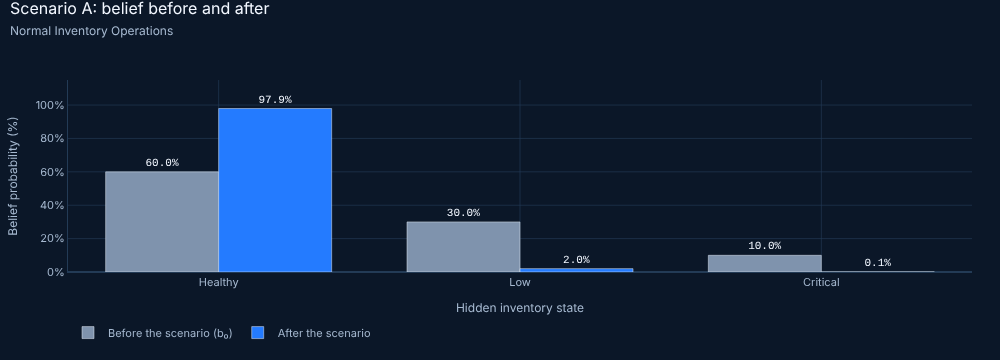

In [23]:
def play(key, config=cfg):
    # Replay a scripted scenario through the shared engine and return (engine, event table).
    engine = SentinelEngine(config)
    engine.play_scenario(SCENARIOS[key])
    t = engine.timeline_frame()
    table = pd.DataFrame({
        "Event": t["label"], "Kind": t["kind"], "Period": t["period"],
        "P(Healthy)": t["b_healthy"], "P(Low)": t["b_low"], "P(Critical)": t["b_critical"],
        "Recommended action": t["recommended_name"], f"Expected cost ({COST_UNIT})": t["expected_cost"],
    })
    return engine, table


def report(key, chart_name, stages=None):
    # Show the event table, a before/after belief chart and the engine's explanation.
    scenario = SCENARIOS[key]
    engine, table = play(key)
    display(Markdown(f"**Scenario {scenario.notebook_label}: {scenario.name}.** {scenario.description}"))
    display(table.style.hide(axis="index").format({"P(Healthy)": "{:.1%}", "P(Low)": "{:.1%}", "P(Critical)": "{:.1%}",
                                                   f"Expected cost ({COST_UNIT})": "{:.2f}"}))
    first, last = table.iloc[0], table.iloc[-1]
    changed = "changed" if first["Recommended action"] != last["Recommended action"] else "did not change"
    display(Markdown(
        f"Belief before: **{format_belief(b0)}** → after: **{format_belief(engine.belief)}** (Healthy / Low / Critical). "
        f"Recommendation {changed}: **{first['Recommended action']} → {last['Recommended action']}**; it switched "
        f"{engine.policy_changes} time(s) along the way.\n\n> {engine.explanation()['paragraph']}"))
    show(viz.fig_before_after(stages or {"Before the scenario (b₀)": b0, "After the scenario": engine.belief},
                              f"Scenario {scenario.notebook_label}: belief before and after — {scenario.name}"),
         chart_name)
    return engine


engine_a = report("normal_ops", "10_scenario_A")

**Scenario A – interpretation.** Four nominal readings move the belief sharply towards Healthy, and repeated normal readings over the next two periods keep it there. Between periods, the *prediction* step pulls the belief slightly back towards Low and Critical (stock depletes when nothing is ordered), and each new normal reading restores confidence. The recommendation never changes: with belief concentrated on Healthy, every intervention costs more than the small shortage risk it would remove. An intelligent agent chooses **not** to act when the evidence does not justify the expense.

**Scenario B: Low Reading from an Unreliable Sensor.** A single low-inventory reading arrives from a sensor that is only 30% reliable. The belief should move far less than it would for a trustworthy sensor.

Sensor reliability,P(Healthy),P(Low),P(Critical),Recommended action,Cost advantage over Continue Monitoring (SCU),Belief concentration
30% (unreliable),47.9%,43.1%,9.0%,Standard Reorder,2.03,0.15
95% (trustworthy),25.8%,67.0%,7.2%,Standard Reorder,8.60,0.27


> P(Low) rose from 30.0% to 43.1% (+13.1 pts) after Sensor readings: “Low inventory reading” (30% reliable). Standard Reorder has the lowest expected total cost, 36.9 SCU, against 38.9 SCU for Continue Monitoring (margin 2.0 SCU, 5.5%). It costs 17.9 SCU to execute, but lowers the predicted probability of Critical inventory next period from 19.8% (if we only monitor) to 7.5%, saving an expected 19.9 SCU of holding-and-shortage cost. This replaces the previous recommendation, Continue Monitoring.

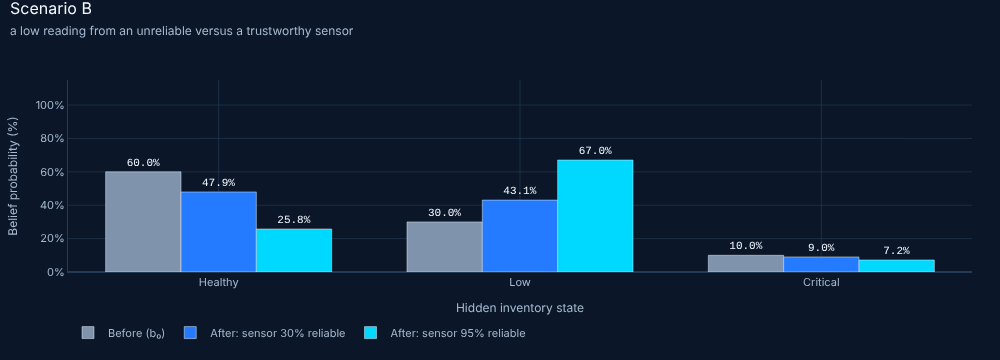

In [24]:
weak, strong = SentinelEngine(cfg), SentinelEngine(cfg)
weak_result = weak.inject_alert("sensor", "Low inventory reading", reliability=0.30)
strong_result = strong.inject_alert("sensor", "Low inventory reading", reliability=0.95)
scenario_b = pd.DataFrame({
    "Sensor reliability": ["30% (unreliable)", "95% (trustworthy)"],
    "P(Healthy)": [weak.belief[0], strong.belief[0]], "P(Low)": [weak.belief[1], strong.belief[1]],
    "P(Critical)": [weak.belief[2], strong.belief[2]],
    "Recommended action": [weak.decision.action_name, strong.decision.action_name],
    f"Cost advantage over Continue Monitoring ({COST_UNIT})": [
        weak.decision.q_values[0] - weak.decision.expected_cost,
        strong.decision.q_values[0] - strong.decision.expected_cost],
    "Belief concentration": [belief_concentration(weak.belief), belief_concentration(strong.belief)],
})
display(Markdown(f"**Scenario B: {SCENARIOS['unreliable_sensor'].name}.** {SCENARIOS['unreliable_sensor'].description}"))
display(scenario_b.style.hide(axis="index").format({"P(Healthy)": "{:.1%}", "P(Low)": "{:.1%}", "P(Critical)": "{:.1%}",
                                                    f"Cost advantage over Continue Monitoring ({COST_UNIT})": "{:.2f}",
                                                    "Belief concentration": "{:.2f}"}))
display(Markdown(f"> {weak.explanation()['paragraph']}"))
show(viz.fig_before_after({"Before (b₀)": b0, "After: sensor 30% reliable": weak.belief,
                           "After: sensor 95% reliable": strong.belief},
                          "Scenario B: a low reading from an unreliable versus a trustworthy sensor"), "11_scenario_B")
engine_b = play("unreliable_sensor")[0]
assert np.allclose(engine_b.belief, weak.belief)          # the preset is exactly the 30% case

**Scenario B – interpretation.** The same reading moves P(Low) far less when the sensor is only 30% reliable than when it is 95% reliable. Both cases tip the recommendation to a standard reorder, because $b_0$ sits close to a decision boundary (Section 7.2), but the strength of the case differs: with the unreliable sensor, reordering is only slightly cheaper in expectation than continuing to monitor, while with the trustworthy sensor the advantage is several times larger. A decision-maker reading the dashboard can see that the first recommendation rests on thin evidence.

**Scenario C: Unexpected Supplier Delay.** The supplier reports a significant delay, followed one period later by a cancellation and a low sensor reading.

Event,Kind,Period,P(Healthy),P(Low),P(Critical),Recommended action,Expected cost (SCU)
Session initialised with the prior belief,init,0,60.0%,30.0%,10.0%,Continue Monitoring,34.59
Supplier updates: Significant delivery delay,alert,0,37.0%,40.2%,22.8%,Standard Reorder,44.47
Executed Standard Reorder; belief predicted for period 1,predict,1,57.9%,29.4%,12.7%,Standard Reorder,37.62
Supplier updates: Supplier cancellation,alert,1,38.3%,33.5%,28.2%,Adjust Production / Reallocate Stock,46.32
Sensor readings: Low inventory reading,alert,1,15.7%,65.7%,18.6%,Standard Reorder,44.60


Belief before: **60.0% / 30.0% / 10.0%** → after: **15.7% / 65.7% / 18.6%** (Healthy / Low / Critical). Recommendation changed: **Continue Monitoring → Standard Reorder**; it switched 3 time(s) along the way.

> P(Healthy) fell from 57.9% to 15.7% (-42.2 pts) after Sensor readings: “Low inventory reading” (90% reliable); Supplier updates: “Supplier cancellation” (85% reliable). Standard Reorder has the lowest expected total cost, 44.6 SCU, against 44.8 SCU for Adjust Production / Reallocate Stock (margin 0.2 SCU, 0.5%). It costs 15.9 SCU to execute, but lowers the predicted probability of Critical inventory next period from 33.5% (if we only monitor) to 12.8%, saving an expected 32.2 SCU of holding-and-shortage cost. This replaces the previous recommendation, Adjust Production / Reallocate Stock.

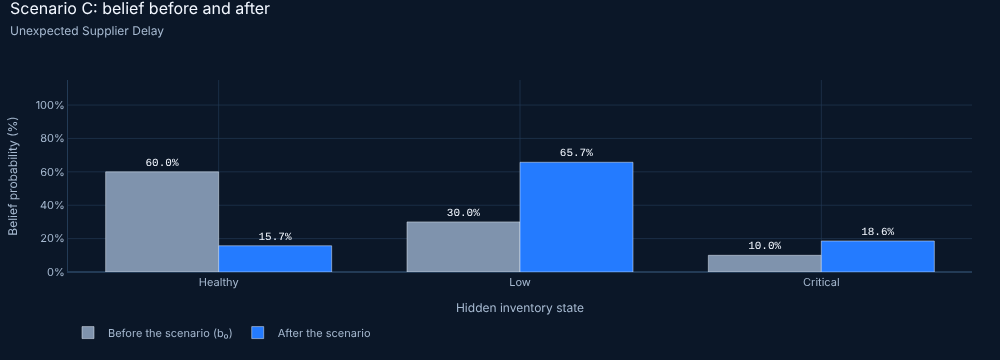

In [25]:
engine_c = report("supplier_delay", "12_scenario_C")

**Scenario C – interpretation.** A significant delay is moderately diagnostic: it more than doubles P(Critical) and is enough to switch the recommendation from monitoring to a standard reorder. That reorder is then *executed*, and the prediction step shows its expected benefit (P(Healthy) rises, P(Critical) falls). The supplier then cancels. The cancellation undermines the benefit just predicted, and the recommendation moves to reallocating internal stock, the action that does not depend on the supplier. A low sensor reading finally concentrates belief on Low, where a standard reorder is again cheapest. Supplier news affects the belief through its statistical association with depleted stock; it is weaker evidence than a direct sensor reading, as the smaller belief shifts show.

**Scenario D: Demand Surge.** Demand moves from moderately elevated to an unexpected surge, with a low sensor reading arriving alongside the surge.

Event,Kind,Period,P(Healthy),P(Low),P(Critical),Recommended action,Expected cost (SCU)
Session initialised with the prior belief,init,0,60.0%,30.0%,10.0%,Continue Monitoring,34.59
Demand signals: Moderately elevated demand,alert,0,55.3%,34.9%,9.8%,Continue Monitoring,36.47
Executed Continue Monitoring; belief predicted for period 1,predict,1,48.8%,32.5%,18.7%,Standard Reorder,41.34
Demand signals: Unexpected demand surge,alert,1,30.8%,34.5%,34.7%,Adjust Production / Reallocate Stock,48.79
Sensor readings: Low inventory reading,alert,1,12.2%,65.6%,22.2%,Adjust Production / Reallocate Stock,46.15


Belief before: **60.0% / 30.0% / 10.0%** → after: **12.2% / 65.6% / 22.2%** (Healthy / Low / Critical). Recommendation changed: **Continue Monitoring → Adjust Production / Reallocate Stock**; it switched 2 time(s) along the way.

> P(Healthy) fell from 48.8% to 12.2% (-36.6 pts) after Sensor readings: “Low inventory reading” (90% reliable); Demand signals: “Unexpected demand surge” (80% reliable). Adjust Production / Reallocate Stock has the lowest expected total cost, 46.2 SCU, against 46.7 SCU for Standard Reorder (margin 0.5 SCU, 1.1%). It costs 22.6 SCU to execute, but lowers the predicted probability of Critical inventory next period from 36.6% (if we only monitor) to 9.6%, saving an expected 41.8 SCU of holding-and-shortage cost. Although Adjust Production / Reallocate Stock has a higher direct cost than Standard Reorder, the stronger recovery more than pays for it at this level of Critical risk.

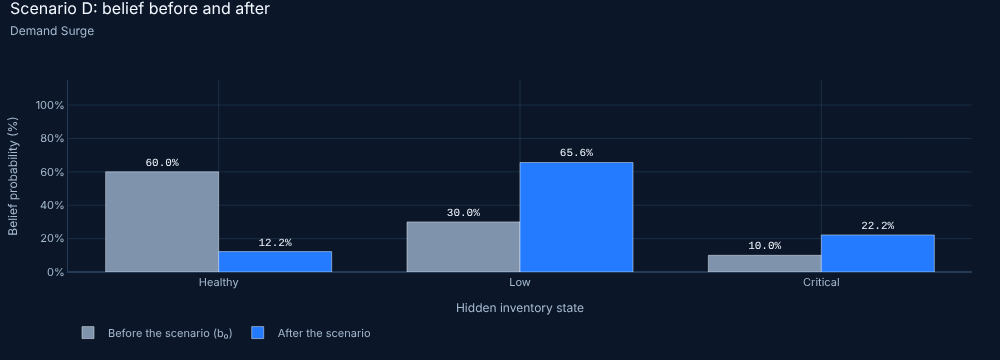

In [26]:
engine_d = report("demand_surge", "13_scenario_D")

**Scenario D – interpretation.** A moderately elevated demand signal on its own barely moves the belief and the agent keeps monitoring: demand signals are the least reliable channel in this model. After a period of monitoring, an unexpected surge arrives. The prediction step has already raised P(Critical), and the surge raises it further, so the recommendation escalates. The low sensor reading that accompanies the surge then pulls mass from Critical to Low. Evidence can therefore *reduce* urgency as well as raise it.

**Scenario E: Critical Inventory Warning.** The sensor issues a critical inventory warning and the monitoring system raises a critical stock warning in the same period.

Event,Kind,Period,P(Healthy),P(Low),P(Critical),Recommended action,Expected cost (SCU)
Session initialised with the prior belief,init,0,60.0%,30.0%,10.0%,Continue Monitoring,34.59
Sensor readings: Critical inventory warning,alert,0,22.8%,29.2%,48.0%,Adjust Production / Reallocate Stock,53.29
System alerts: Critical stock warning,alert,0,3.3%,12.1%,84.7%,Expedite Supplier Delivery,59.55


Belief before: **60.0% / 30.0% / 10.0%** → after: **3.3% / 12.1% / 84.7%** (Healthy / Low / Critical). Recommendation changed: **Continue Monitoring → Expedite Supplier Delivery**; it switched 2 time(s) along the way.

> P(Critical) rose from 10.0% to 84.7% (+74.7 pts) after Sensor readings: “Critical inventory warning” (90% reliable); System alerts: “Critical stock warning” (90% reliable). Expedite Supplier Delivery has the lowest expected total cost, 59.5 SCU, against 65.6 SCU for Adjust Production / Reallocate Stock (margin 6.1 SCU, 10.2%). It costs 40.3 SCU to execute, but lowers the predicted probability of Critical inventory next period from 79.3% (if we only monitor) to 7.2%, saving an expected 103.2 SCU of holding-and-shortage cost. Although Expedite Supplier Delivery has a higher direct cost than Adjust Production / Reallocate Stock, the stronger recovery more than pays for it at this level of Critical risk. This replaces the previous recommendation, Adjust Production / Reallocate Stock.

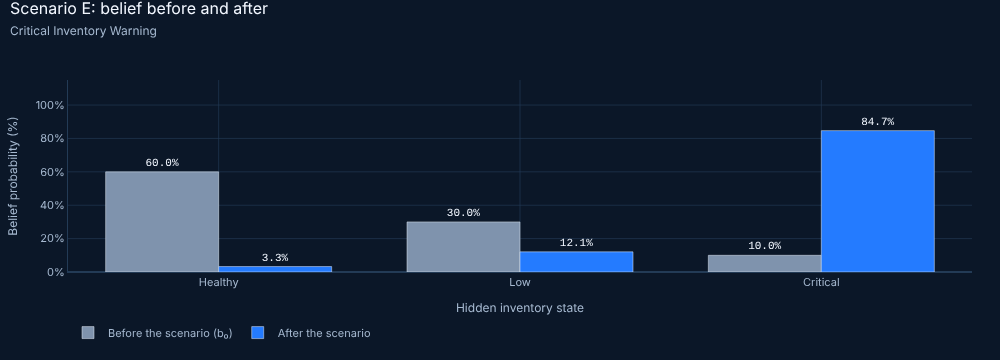

In [27]:
engine_e = report("critical_warning", "14_scenario_E")

**Scenario E – interpretation.** A sensor critical warning takes P(Critical) from 10% to roughly half; a critical stock warning from the monitoring system, an independent channel under the model's assumption, takes it above 80%. The recommendation moves in two steps, first to reallocation and then to **Expedite Supplier Delivery**. Expediting is the most expensive action to execute, yet it has the lowest expected *total* cost once Critical is this probable, because the stock-out penalty it avoids dominates the premium. The infographic's "emergency replenishment" branch hints at this cost trade-off; here it is derived from the numbers.

**Scenario F: Conflicting Sensor Evidence.** The sensor reads normal while the monitoring system raises a critical stock warning and the supplier reports a significant delay. The channels disagree; Bayes weighs them by likelihood.

Event,Kind,Period,P(Healthy),P(Low),P(Critical),Recommended action,Expected cost (SCU)
Session initialised with the prior belief,init,0,60.0%,30.0%,10.0%,Continue Monitoring,34.59
Sensor readings: Normal inventory reading,alert,0,89.2%,9.6%,1.2%,Continue Monitoring,14.65
System alerts: Critical stock warning,alert,0,67.6%,21.0%,11.4%,Continue Monitoring,32.55
Supplier updates: Significant delivery delay,alert,0,43.5%,29.4%,27.1%,Adjust Production / Reallocate Stock,45.68
Demand signals: Normal demand,alert,0,61.4%,25.0%,13.6%,Continue Monitoring,37.08


Belief before: **60.0% / 30.0% / 10.0%** → after: **61.4% / 25.0% / 13.6%** (Healthy / Low / Critical). Recommendation did not change: **Continue Monitoring → Continue Monitoring**; it switched 2 time(s) along the way.

> P(Low) fell from 30.0% to 25.0% (-5.0 pts) after Sensor readings: “Normal inventory reading” (90% reliable); System alerts: “Critical stock warning” (90% reliable); Supplier updates: “Significant delivery delay” (85% reliable); 1 further observation(s). Continue Monitoring has the lowest expected total cost, 37.1 SCU, against 37.7 SCU for Standard Reorder (margin 0.6 SCU, 1.7%). Intervening with Standard Reorder would cut the expected holding-and-shortage cost by only 18.1 SCU while adding 18.7 SCU of ordering and surplus cost, so waiting for more evidence is cheaper under the current belief. This replaces the previous recommendation, Adjust Production / Reallocate Stock.

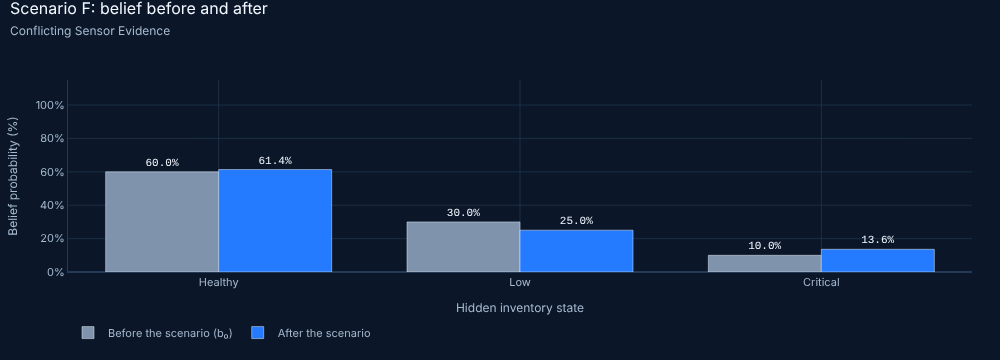

In [28]:
engine_f = report("conflicting", "15_scenario_F")

**Scenario F – interpretation.** The channels disagree: the sensor says normal, the monitoring system says critical, the supplier reports a significant delay and demand looks normal. Bayes' rule does not pick a winner or take a vote. It multiplies likelihoods, so each channel counts in proportion to how diagnostic and how reliable it is. The belief swings as the alerts arrive and the recommendation changes twice, ending back at monitoring with a noticeably more spread-out belief than Scenario A produced. The agent is honest about not knowing: the conflict shows up as higher uncertainty and a smaller decision margin, not as false confidence.

**Scenario G: Multiple Consecutive Alerts.** Five periods of mostly worsening evidence while the operator only monitors (manual override). Shows the belief drifting towards Critical and the recommendation escalating.

Event,Kind,Period,P(Healthy),P(Low),P(Critical),Recommended action,Expected cost (SCU)
Session initialised with the prior belief,init,0,60.0%,30.0%,10.0%,Continue Monitoring,34.59
Demand signals: Moderately elevated demand,alert,0,55.3%,34.9%,9.8%,Continue Monitoring,36.47
Executed Continue Monitoring; belief predicted for period 1,predict,1,48.8%,32.5%,18.7%,Standard Reorder,41.34
Supplier updates: Minor delivery delay,alert,1,40.5%,40.2%,19.3%,Standard Reorder,42.46
Sensor readings: Normal inventory reading,alert,1,79.9%,17.0%,3.1%,Continue Monitoring,20.24
Executed Continue Monitoring; belief predicted for period 2,predict,2,68.8%,22.6%,8.6%,Continue Monitoring,29.69
Sensor readings: Low inventory reading,alert,2,36.1%,56.6%,7.3%,Standard Reorder,37.24
Demand signals: High demand,alert,2,23.8%,64.9%,11.3%,Standard Reorder,40.37
Executed Continue Monitoring; belief predicted for period 3,predict,3,23.6%,49.5%,26.9%,Adjust Production / Reallocate Stock,46.86
Supplier updates: Significant delivery delay,alert,3,10.2%,46.7%,43.1%,Adjust Production / Reallocate Stock,52.62


Belief before: **60.0% / 30.0% / 10.0%** → after: **0.0% / 2.7% / 97.2%** (Healthy / Low / Critical). Recommendation changed: **Continue Monitoring → Expedite Supplier Delivery**; it switched 5 time(s) along the way.

> P(Critical) rose from 46.1% to 97.2% (+51.1 pts) after Sensor readings: “Critical inventory warning” (90% reliable); System alerts: “Critical stock warning” (90% reliable); Demand signals: “Unexpected demand surge” (80% reliable). Expedite Supplier Delivery has the lowest expected total cost, 60.6 SCU, against 69.7 SCU for Adjust Production / Reallocate Stock (margin 9.1 SCU, 15.0%). It costs 40.0 SCU to execute, but lowers the predicted probability of Critical inventory next period from 88.2% (if we only monitor) to 7.9%, saving an expected 113.9 SCU of holding-and-shortage cost. Although Expedite Supplier Delivery has a higher direct cost than Adjust Production / Reallocate Stock, the stronger recovery more than pays for it at this level of Critical risk.

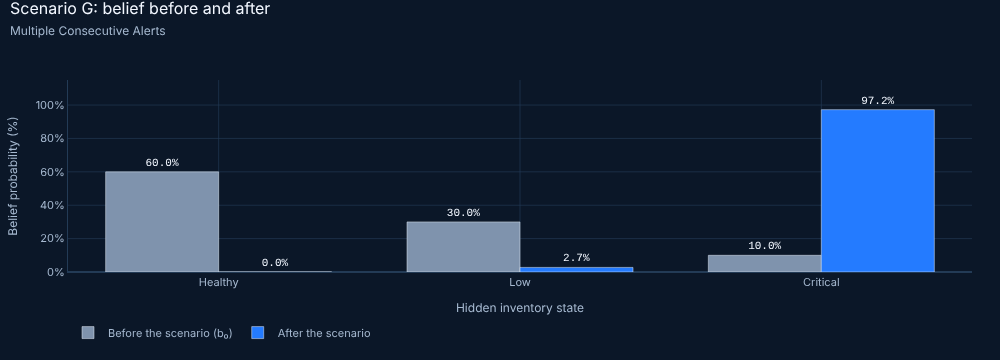

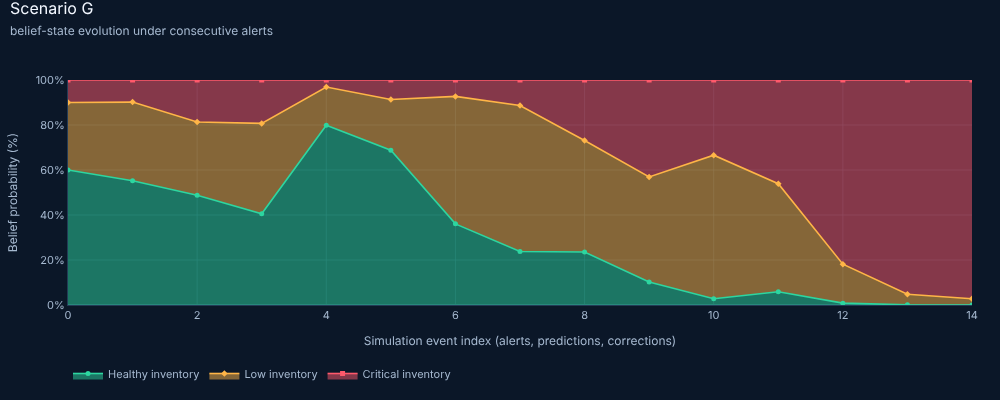

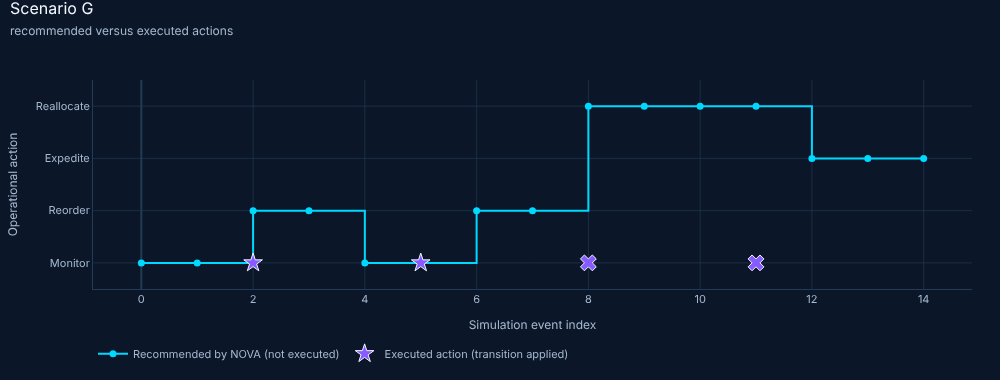

In [29]:
engine_g = report("consecutive", "16_scenario_G")
show(viz.fig_belief_evolution(engine_g.timeline_frame(), "Scenario G: belief-state evolution under consecutive alerts"),
     "17_scenario_G_evolution")
show(viz.fig_policy_timeline(engine_g.timeline_frame(), engine_g.action_history(),
                             "Scenario G: recommended versus executed actions"), "18_scenario_G_policy")

**Scenario G – interpretation.** Here the operator ignores the recommendation and only monitors for four periods (a manual override), while the evidence mostly worsens. The belief-evolution chart shows the coral Critical band widening over the periods, with one brief reprieve when a normal sensor reading arrives in period 1: each prediction step under Continue Monitoring adds depletion risk, and each adverse alert adds more. The policy chart separates the two things the brief asks to keep apart. The cyan line is what NOVA **recommended** (escalating from monitoring through reorder and reallocation to expediting); the markers are what was actually **executed** (monitoring every time; a × marks each period in which that differed from the recommendation). The belief is predicted with the executed action's transition model, never with the recommended one.

**Scenario H: Successful Replenishment and Recovery.** A critical picture triggers an intervention; the recommended action is executed and the following periods bring improving evidence.

Event,Kind,Period,P(Healthy),P(Low),P(Critical),Recommended action,Expected cost (SCU)
Session initialised with the prior belief,init,0,60.0%,30.0%,10.0%,Continue Monitoring,34.59
Sensor readings: Critical inventory warning,alert,0,22.8%,29.2%,48.0%,Adjust Production / Reallocate Stock,53.29
System alerts: Critical stock warning,alert,0,3.3%,12.1%,84.7%,Expedite Supplier Delivery,59.55
Supplier updates: Significant delivery delay,alert,0,1.0%,7.7%,91.4%,Expedite Supplier Delivery,60.07
Executed Expedite Supplier Delivery; belief predicted for period 1,predict,1,61.5%,31.0%,7.5%,Continue Monitoring,31.87
Sensor readings: Low inventory reading,alert,1,27.7%,66.8%,5.5%,Standard Reorder,37.22
Supplier updates: Delivery on schedule,alert,1,41.5%,56.5%,2.1%,Standard Reorder,34.24
Executed Standard Reorder; belief predicted for period 2,predict,2,67.1%,27.1%,5.8%,Continue Monitoring,27.95
Sensor readings: Normal inventory reading,alert,2,91.4%,7.9%,0.6%,Continue Monitoring,13.21
System alerts: No anomaly,alert,2,97.4%,2.6%,0.1%,Continue Monitoring,10.18


Belief before: **60.0% / 30.0% / 10.0%** → after: **96.3% / 3.4% / 0.2%** (Healthy / Low / Critical). Recommendation did not change: **Continue Monitoring → Continue Monitoring**; it switched 5 time(s) along the way.

> P(Healthy) rose from 83.7% to 96.3% (+12.6 pts) after Sensor readings: “Normal inventory reading” (90% reliable). Continue Monitoring has the lowest expected total cost, 10.8 SCU, against 27.9 SCU for Standard Reorder (margin 17.1 SCU, 159.4%). Intervening with Standard Reorder would cut the expected holding-and-shortage cost by only 3.6 SCU while adding 20.8 SCU of ordering and surplus cost, so waiting for more evidence is cheaper under the current belief.

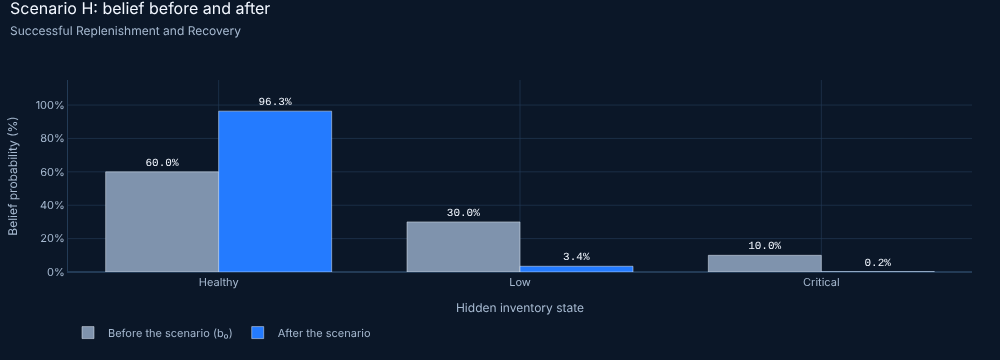

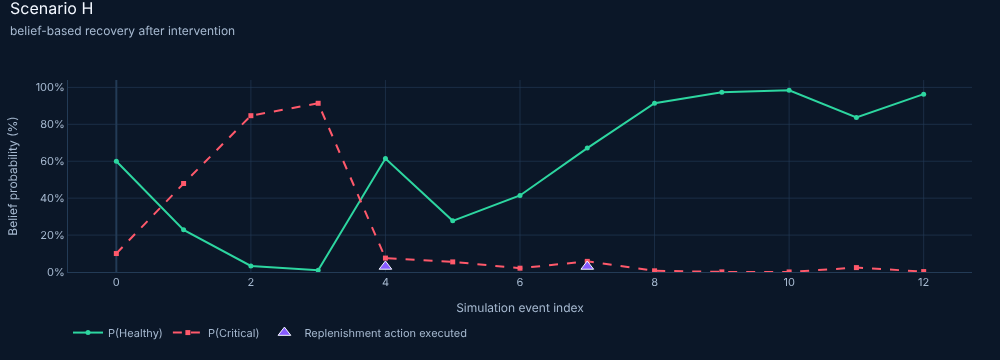

Period,Recommended action,Executed action,Followed recommendation,Predicted outcome (H / L / C),Observed subsequent evidence,Posterior after evidence (H / L / C)
0,Expedite Supplier Delivery,Expedite Supplier Delivery,yes,61.5% / 31.0% / 7.5%,Sensor readings: Low inventory reading; Supplier updates: Delivery on schedule,41.5% / 56.5% / 2.1%
1,Standard Reorder,Standard Reorder,yes,67.1% / 27.1% / 5.8%,Sensor readings: Normal inventory reading; System alerts: No anomaly; Demand signals: Normal demand,98.4% / 1.6% / 0.0%
2,Continue Monitoring,Continue Monitoring,yes,83.7% / 13.9% / 2.4%,Sensor readings: Normal inventory reading,96.3% / 3.4% / 0.2%


In [30]:
engine_h = report("recovery", "19_scenario_H")
show(viz.fig_recovery_trend(engine_h.timeline_frame(), "Scenario H: belief-based recovery after intervention"),
     "20_scenario_H_recovery")
display(engine_h.action_log_frame()[["Period", "Recommended action", "Executed action", "Followed recommendation",
                                     "Predicted outcome (H / L / C)", "Observed subsequent evidence",
                                     "Posterior after evidence (H / L / C)"]].style.hide(axis="index"))

**Scenario H – interpretation.** Critical evidence drives the recommendation to Expedite, and this time the recommendation is executed. The action log separates four things: the **recommended** action, the **executed** action, the **predicted outcome** (the belief after the action's transition model) and the **observed subsequent evidence** with the posterior it produced. Expediting is predicted to lift P(Healthy) substantially. The following readings (low, then normal) confirm a partial and then a full recovery, and the agent steps down to a standard reorder and then back to monitoring. Prediction says what the action *should* achieve; only the next observations tell the agent whether it did.

### 8.1 Summary of the eight scenarios

In [31]:
summary_rows = []
for key in NOTEBOOK_SCENARIOS:
    engine, table = play(key)
    summary_rows.append({
        "Scenario": f"{SCENARIOS[key].notebook_label} · {SCENARIOS[key].name}",
        "Alerts": engine.alerts_processed, "Periods": engine.step + 1,
        "Final belief (H / L / C)": format_belief(engine.belief),
        "First recommendation": table["Recommended action"].iloc[0],
        "Final recommendation": engine.decision.action_name,
        "Policy changes": engine.policy_changes,
        "Final belief concentration": round(belief_concentration(engine.belief), 2),
    })
display(pd.DataFrame(summary_rows).style.hide(axis="index"))

Scenario,Alerts,Periods,Final belief (H / L / C),First recommendation,Final recommendation,Policy changes,Final belief concentration
A · Normal Inventory Operations,8,3,97.9% / 2.0% / 0.1%,Continue Monitoring,Continue Monitoring,0,0.910000
B · Low Reading from an Unreliable Sensor,1,1,47.9% / 43.1% / 9.0%,Continue Monitoring,Standard Reorder,1,0.150000
C · Unexpected Supplier Delay,3,2,15.7% / 65.7% / 18.6%,Continue Monitoring,Standard Reorder,3,0.200000
D · Demand Surge,3,2,12.2% / 65.6% / 22.2%,Continue Monitoring,Adjust Production / Reallocate Stock,2,0.210000
E · Critical Inventory Warning,2,1,3.3% / 12.1% / 84.7%,Continue Monitoring,Expedite Supplier Delivery,2,0.540000
F · Conflicting Sensor Evidence,4,1,61.4% / 25.0% / 13.6%,Continue Monitoring,Continue Monitoring,2,0.160000
G · Multiple Consecutive Alerts,10,5,0.0% / 2.7% / 97.2%,Continue Monitoring,Expedite Supplier Delivery,5,0.880000
H · Successful Replenishment and Recovery,9,4,96.3% / 3.4% / 0.2%,Continue Monitoring,Continue Monitoring,5,0.850000


**Interpretation.** Across the scenarios, the recommendation changes only when the belief crosses a region boundary of the policy map, and all four actions are recommended at some point. Reassuring evidence (A) concentrates the belief and leaves the policy alone; weak or conflicting evidence (B, F) moves the belief modestly and yields narrow margins; strong or accumulating evidence (E, G) escalates the response; and an executed intervention followed by good news (H) brings the agent back to monitoring.

**Link to the assignment objective.** This is the behaviour the brief asks the dashboard to demonstrate: changing alerts dynamically modify the belief state and automatically trigger different operational recommendations.

## 9. Performance evaluation

> Everything in this section is **synthetic simulation output**. It shows how the method behaves inside a simulator built from stated assumptions. It is not evidence about real-world supply-chain performance.

### 9.1 Evaluation protocol

- **Replications.** Each policy is simulated for 300 independent episodes of 60 periods.
- **Common random numbers.** Replication $i$ uses the same seed for every policy, so all policies face the same underlying randomness.
- **Confidence intervals.** Means are reported with 95% Student-$t$ intervals across replications, and differences between policies are tested as *paired* differences.
- **Operational metrics.** *Stock-out frequency* is the share of periods in which demand exceeded that period's synthetic inventory snapshot; *service level* is total units served divided by total units demanded, using the same snapshots. Because snapshots are drawn within the hidden state's band each period (no stock roll-forward), both are state-driven proxies.
- **Belief scoring.** The multiclass Brier score in Brier's (1950) original form, $\text{BS} = \frac{1}{N}\sum_n \sum_r (f_{nr} - y_{nr})^2$ with range $[0, 2]$, and the log loss $-\frac{1}{N}\sum_n \ln b_n(\text{true state})$. Both are strictly proper scoring rules (Gneiting & Raftery, 2007), written here as losses (lower is better). Calibration is assessed with reliability diagrams and Expected Calibration Error (Guo et al., 2017).

| Policy | What it does | Uses the belief? |
|---|---|---|
| **SENTINEL belief agent (myopic)** | Bayes filter + one-step expected-cost minimisation | Yes |
| QMDP approximation ($\gamma = 0.95$) | Optional comparison: infinite-horizon MDP values weighted by the belief (Littman et al., 1995) | Yes |
| Infographic threshold rule | P(Critical) > 20% → expedite; else P(Low) > 40% → reorder; else monitor | Yes (fixed cut-offs, no cost model) |
| Record-trusting heuristic | Treats the latest sensor reading as the truth | No |
| Fixed: always monitor / always reorder / reorder every 3 periods | Ignore all evidence | No |
| **Full-information myopic oracle** | Sees the hidden state and applies the same one-step rule. Evaluation-only benchmark | n/a |

The oracle is **not implementable** under partial observability and it is not "the optimal policy". It shows what perfect visibility would be worth to a decision-maker using the same one-step rule.

### 9.2 Sanity check of the Brier score

In [32]:
reference = pd.DataFrame({
    "Forecast": ["b₀ = [0.60, 0.30, 0.10]"] * 3 + ["uniform [1/3, 1/3, 1/3]", "certain and right", "certain and wrong"],
    "True state": ["Healthy", "Low", "Critical", "any", "Healthy", "Critical"],
    "Multiclass Brier score (0–2)": list(brier_scores([[0.6, 0.3, 0.1]] * 3, [0, 1, 2])) + [
        brier_score([[1 / 3, 1 / 3, 1 / 3]], [0]), brier_score([[1, 0, 0]], [0]), brier_score([[1, 0, 0]], [2])],
})
display(reference.style.hide(axis="index").format({"Multiclass Brier score (0–2)": "{:.2f}"}))
assert np.allclose(brier_scores([[0.6, 0.3, 0.1]] * 3, [0, 1, 2]), [0.26, 0.86, 1.26])
print("By hand, truth = Critical: (0.6-0)^2 + (0.3-0)^2 + (0.1-1)^2 = 0.36 + 0.09 + 0.81 = 1.26")

Forecast,True state,Multiclass Brier score (0–2)
"b₀ = [0.60, 0.30, 0.10]",Healthy,0.26
"b₀ = [0.60, 0.30, 0.10]",Low,0.86
"b₀ = [0.60, 0.30, 0.10]",Critical,1.26
"uniform [1/3, 1/3, 1/3]",any,0.67
certain and right,Healthy,0.00
certain and wrong,Critical,2.00


By hand, truth = Critical: (0.6-0)^2 + (0.3-0)^2 + (0.1-1)^2 = 0.36 + 0.09 + 0.81 = 1.26


For the initial belief, the scores are **0.26, 0.86 and 1.26** when the truth is Healthy, Low and Critical respectively. The score is 0 for a certain and correct forecast, 2 for a certain and wrong one, and 2/3 for a uniform forecast.

### 9.3 Policy comparison

In [33]:
N_REPLICATIONS, HORIZON = 300, 60
AGENT, ORACLE, RECORD = "SENTINEL belief agent (myopic)", "Full-information myopic oracle", "Record-trusting heuristic"
policy_factories = {
    AGENT: lambda m: BeliefMyopicPolicy(m.transition, m.cost),
    "QMDP approximation (γ = 0.95)": lambda m: QMDPPolicy(m.transition, m.cost, cfg.discount),
    "Infographic threshold rule": lambda m: InfographicThresholdPolicy(),
    RECORD: lambda m: RecordTrustingPolicy(),
    "Fixed: always reorder": lambda m: FixedPolicy("reorder"),
    "Fixed: reorder every 3 periods": lambda m: PeriodicReorderPolicy(3),
    "Fixed: always monitor": lambda m: FixedPolicy("monitor"),
    ORACLE: lambda m: OraclePolicy(m.transition, m.cost),
}
results, trajectories = evaluate_policies(cfg, policy_factories, n_replications=N_REPLICATIONS, horizon=HORIZON,
                                          seed=SEED, keep_trajectories=True)
summary = summarise_replications(results)

table = summary[["policy", "total_cost", "total_cost_ci", "stockout_rate", "service_level", "critical_share",
                 "intervention_rate"]].copy()
table.columns = ["Policy", f"Mean total cost ({COST_UNIT})", "± 95% CI", "Stock-out frequency",
                 "Service level (fill rate)", "Share of periods Critical", "Intervention rate"]
print(f"Synthetic simulation output: {N_REPLICATIONS} replications x {HORIZON} periods per policy, common random numbers")
display(table.style.hide(axis="index").format({
    f"Mean total cost ({COST_UNIT})": "{:,.0f}", "± 95% CI": "{:,.0f}", "Stock-out frequency": "{:.1%}",
    "Service level (fill rate)": "{:.1%}", "Share of periods Critical": "{:.1%}", "Intervention rate": "{:.1%}"}))

Synthetic simulation output: 300 replications x 60 periods per policy, common random numbers


Policy,Mean total cost (SCU),± 95% CI,Stock-out frequency,Service level (fill rate),Share of periods Critical,Intervention rate
SENTINEL belief agent (myopic),"1,297",50,8.0%,94.7%,6.3%,24.7%
QMDP approximation (γ = 0.95),"1,217",42,6.0%,96.1%,4.5%,29.3%
Infographic threshold rule,"1,263",47,7.2%,95.2%,5.6%,24.2%
Record-trusting heuristic,"1,369",47,6.8%,95.5%,5.3%,32.5%
Fixed: always reorder,"1,827",36,4.1%,97.3%,3.2%,100.0%
Fixed: reorder every 3 periods,"2,491",117,20.0%,86.5%,18.5%,33.3%
Fixed: always monitor,"5,547",168,55.6%,63.4%,57.0%,0.0%
Full-information myopic oracle,986,38,5.3%,96.7%,3.6%,22.7%


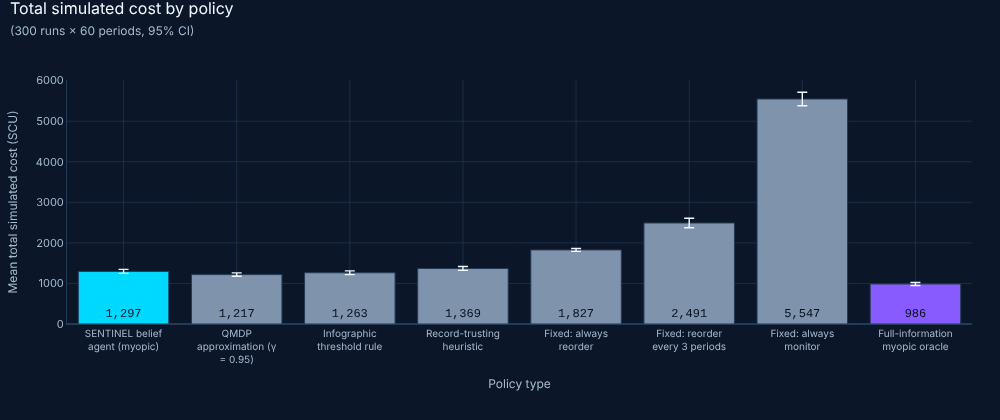

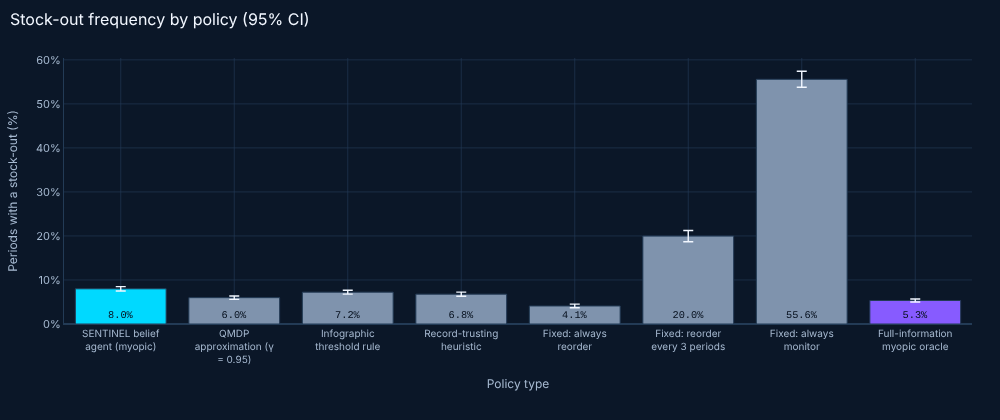

In [34]:
show(viz.fig_policy_comparison(summary, "total_cost",
                               f"Total simulated cost by policy ({N_REPLICATIONS} runs × {HORIZON} periods, 95% CI)",
                               highlight=AGENT), "21_policy_cost_comparison")
show(viz.fig_policy_comparison(summary, "stockout_rate", "Stock-out frequency by policy (95% CI)",
                               y_title="Periods with a stock-out (%)", highlight=AGENT, percent=True),
     "22_policy_stockout_comparison")

In [35]:
cost = summary.set_index("policy")["total_cost"]
rows = []
for name in policy_factories:
    if name == AGENT:
        continue
    diff = paired_difference(results, name, AGENT, "total_cost")
    rows.append({"Compared policy": name, f"Its mean cost ({COST_UNIT})": cost[name],
                 f"Paired difference: policy − agent ({COST_UNIT})": diff["mean"], "95% CI low": diff["low"],
                 "95% CI high": diff["high"],
                 "Agent significantly cheaper?": "yes" if diff["low"] > 0 else ("no (agent dearer)" if diff["high"] < 0 else "not significant"),
                 "Gap to oracle closed by agent": gap_closed(cost[name], cost[AGENT], cost[ORACLE]) if name != ORACLE else np.nan})
paired = pd.DataFrame(rows)
display(paired.style.hide(axis="index").format({
    f"Its mean cost ({COST_UNIT})": "{:,.0f}", f"Paired difference: policy − agent ({COST_UNIT})": "{:+,.0f}",
    "95% CI low": "{:+,.0f}", "95% CI high": "{:+,.0f}", "Gap to oracle closed by agent": "{:.0%}"}, na_rep="—"))

agent_row, oracle_row = summary.set_index("policy").loc[AGENT], summary.set_index("policy").loc[ORACLE]
display(Markdown(
    f"**Experimental result (synthetic).** The belief agent's mean total cost is **{agent_row['total_cost']:,.0f} {COST_UNIT}** "
    f"(±{agent_row['total_cost_ci']:,.0f}), with a stock-out in {agent_row['stockout_rate']:.1%} of periods and a "
    f"{agent_row['service_level']:.1%} fill rate, while intervening in only {agent_row['intervention_rate']:.0%} of periods. "
    f"The full-information oracle achieves {oracle_row['total_cost']:,.0f} {COST_UNIT}, so not seeing the state costs the agent "
    f"about {agent_row['total_cost'] / oracle_row['total_cost'] - 1:.0%} more than perfect visibility would."))

Compared policy,Its mean cost (SCU),Paired difference: policy − agent (SCU),95% CI low,95% CI high,Agent significantly cheaper?,Gap to oracle closed by agent
QMDP approximation (γ = 0.95),"1,217",-80,-101,-59,no (agent dearer),-35%
Infographic threshold rule,"1,263",-34,-49,-19,no (agent dearer),-12%
Record-trusting heuristic,"1,369",+72,+49,+95,yes,19%
Fixed: always reorder,"1,827",+530,+491,+568,yes,63%
Fixed: reorder every 3 periods,"2,491","+1,194","+1,099","+1,288",yes,79%
Fixed: always monitor,"5,547","+4,250","+4,100","+4,400",yes,93%
Full-information myopic oracle,986,-311,-337,-285,no (agent dearer),—


**Experimental result (synthetic).** The belief agent's mean total cost is **1,297 SCU** (±50), with a stock-out in 8.0% of periods and a 94.7% fill rate, while intervening in only 25% of periods. The full-information oracle achieves 986 SCU, so not seeing the state costs the agent about 32% more than perfect visibility would.

**Interpretation (read together with the table above; a positive paired difference means the agent is cheaper).**

- **Against evidence-blind rules** the belief agent is far cheaper. Never ordering lets stock collapse. Always ordering buys the highest service level at a much higher cost, because it pays for replenishment in every period, including the many in which stock is already healthy.
- **Against the record-trusting heuristic** the agent is significantly cheaper (the confidence interval of the paired difference excludes zero) and it intervenes in fewer periods. The heuristic achieves a slightly *lower* stock-out frequency, but it buys that by over-ordering whenever a noisy reading looks bad, so its total cost is higher.
- **Against the infographic threshold rule and QMDP** the myopic agent **loses**, by a small but statistically significant margin. Both rivals use the *same* Bayesian belief, so they benefit equally from the filter; the difference is in the action rule. Critical inventory is persistent in this environment, so taking action before the one-step policy would otherwise recommend it can pay off over several periods. QMDP captures that with multi-period values, and the infographic's fixed thresholds happen to be more aggressive than the cost-based boundaries at these particular costs. This is the price of myopia, the same qualitative effect that Mersereau (2013) analyses for inventory with inaccurate records.
- **Against the oracle** every implementable policy loses. The remaining gap is the value of the information the agent lacks.

The lesson for the assignment is that the *belief state* is what separates the three best implementable policies from the rest. The choice of action rule on top of the belief matters less, and the transparent one-step rule is a reasonable choice, but not the best one.

### 9.4 Quality of the belief: accuracy, Brier score, log loss and calibration

In [36]:
agent_path = trajectories[AGENT]
beliefs, truth = agent_path[BELIEF_COLUMNS].to_numpy(), agent_path["hidden_state"].to_numpy()
base_rates = np.bincount(truth, minlength=3) / len(truth)
constant = np.tile(base_rates, (len(truth), 1))              # a forecaster who always states the base rates
uniform = np.full_like(beliefs, 1 / 3)
latest_sensor = agent_path["obs_sensor"].to_numpy()

per_replication = results[results["policy"] == AGENT]
quality = pd.DataFrame({
    "Forecaster": ["SENTINEL Bayes filter", "Constant base rates (no evidence)", "Uniform (knows nothing)"],
    "Accuracy of most probable state": [map_accuracy(beliefs, truth), map_accuracy(constant, truth), 1 / 3],
    "Brier score (0–2)": [brier_score(beliefs, truth), brier_score(constant, truth), brier_score(uniform, truth)],
    "Log loss": [log_loss(beliefs, truth), log_loss(constant, truth), log_loss(uniform, truth)],
})
display(quality.style.hide(axis="index").format({"Accuracy of most probable state": "{:.1%}",
                                                 "Brier score (0–2)": "{:.3f}", "Log loss": "{:.3f}"}))
for metric, label in (("brier", "Brier score"), ("log_loss", "Log loss"), ("accuracy", "Accuracy")):
    ci = mean_confidence_interval(per_replication[metric])
    print(f"{label:12s} per replication: {ci['mean']:.3f}  (95% CI {ci['low']:.3f} to {ci['high']:.3f}, n = {ci['n']})")
sensor_only_accuracy = float(np.mean(np.where(latest_sensor == 3, 0, latest_sensor)[latest_sensor >= 0]
                                     == truth[latest_sensor >= 0]))
print(f"Reading the latest sensor value as the state is right {sensor_only_accuracy:.1%} of the time "
      f"(base rates: Healthy {base_rates[0]:.1%}, Low {base_rates[1]:.1%}, Critical {base_rates[2]:.1%}).")

Forecaster,Accuracy of most probable state,Brier score (0–2),Log loss
SENTINEL Bayes filter,84.6%,0.220,0.384
Constant base rates (no evidence),72.2%,0.428,0.739
Uniform (knows nothing),33.3%,0.667,1.099


Brier score  per replication: 0.220  (95% CI 0.212 to 0.229, n = 300)
Log loss     per replication: 0.384  (95% CI 0.370 to 0.398, n = 300)
Accuracy     per replication: 0.846  (95% CI 0.839 to 0.853, n = 300)
Reading the latest sensor value as the state is right 76.5% of the time (base rates: Healthy 72.2%, Low 21.4%, Critical 6.3%).


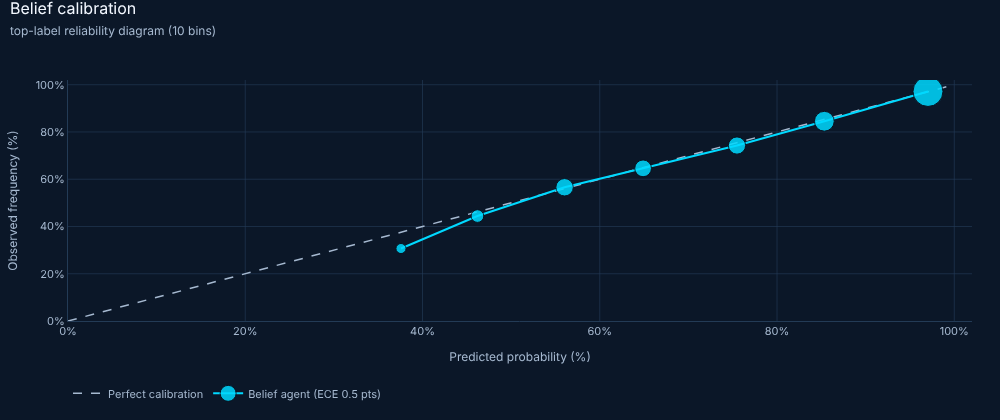

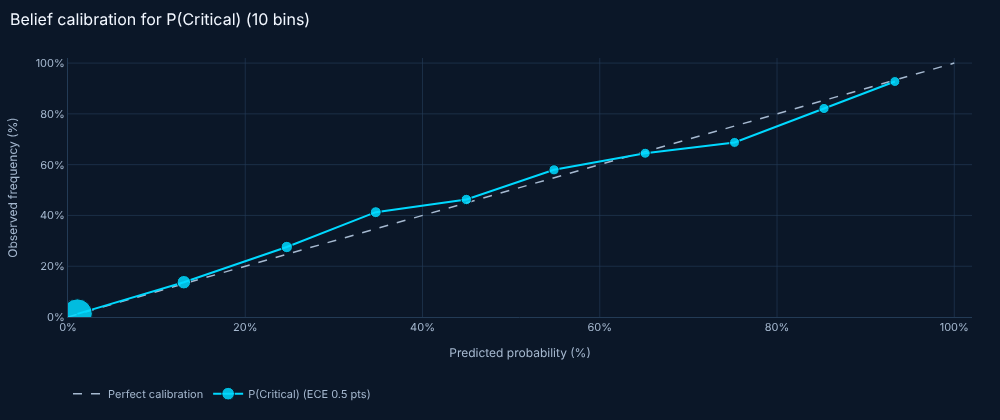

Expected Calibration Error: top label 0.005, P(Critical) 0.005  (10 equal-width bins, 18,000 belief-state pairs)


In [37]:
top_label = calibration_table(beliefs, truth, n_bins=10, mode="top_label")
ece_top = expected_calibration_error(top_label)
critical_cal = calibration_table(beliefs, truth, n_bins=10, mode="state", state=2)
ece_critical = expected_calibration_error(critical_cal)
show(viz.fig_calibration(top_label, "Belief calibration: top-label reliability diagram (10 bins)", ece_top),
     "23_calibration_top_label")
show(viz.fig_calibration(critical_cal, "Belief calibration for P(Critical) (10 bins)", ece_critical,
                         series_name="P(Critical)"), "24_calibration_critical")
print(f"Expected Calibration Error: top label {ece_top:.3f}, P(Critical) {ece_critical:.3f}  "
      f"(10 equal-width bins, {len(truth):,} belief-state pairs)")

**Interpretation.** The Bayes filter is far more accurate and far better scored than a forecaster who only knows the base rates, and it beats reading the latest sensor value as the truth, because it accumulates evidence across channels and over time. In the reliability diagrams, the points lie close to the diagonal: when the agent says 80%, it is right about 80% of the time.

**An important caveat.** The simulator draws states and observations from the *same* model the agent uses. An exact Bayes filter is then calibrated by construction, apart from sampling noise. Good calibration here verifies that the filter is implemented correctly. It says nothing about how well the model matches any real warehouse. The next subsection therefore breaks the match deliberately.

### 9.5 Model-mismatch experiments

In each experiment, the **true** environment differs from the model the agent **assumes**. The agent is not told. Five mismatches are tested against the well-specified case.

In [38]:
mismatches = {
    "Well-specified (truth = agent's model)": EnvironmentOptions(),
    "Sensor less reliable than assumed (60% vs 90%)": EnvironmentOptions(true_reliability={"sensor": 0.60}),
    "All channels less reliable than assumed": EnvironmentOptions(
        true_reliability={"sensor": 0.60, "supplier": 0.55, "demand": 0.50, "system": 0.60}),
    "Correlated alerts: system alert echoes the sensor": EnvironmentOptions(system_echo_probability=1.0),
    "Faster depletion than assumed (true κ = 0.15)": EnvironmentOptions(true_demand_volatility=0.15),
    "Unreliable supplier not modelled (true ρ = 0.40)": EnvironmentOptions(true_supplier_risk=0.40),
}
agent_only = {AGENT: policy_factories[AGENT], ORACLE: policy_factories[ORACLE]}
mismatch_rows, mismatch_calibration = [], {}
for label, options in mismatches.items():
    res, traj = evaluate_policies(cfg, agent_only, n_replications=N_REPLICATIONS, horizon=HORIZON, seed=SEED,
                                  options=options, keep_trajectories=True)
    agent_res = res[res["policy"] == AGENT]
    b, y = traj[AGENT][BELIEF_COLUMNS].to_numpy(), traj[AGENT]["hidden_state"].to_numpy()
    cal = calibration_table(b, y, n_bins=10)
    mismatch_calibration[label] = cal
    cost_ci = mean_confidence_interval(agent_res["total_cost"])
    mismatch_rows.append({
        "True environment": label, f"Agent total cost ({COST_UNIT})": cost_ci["mean"], "± 95% CI": cost_ci["half_width"],
        f"Oracle total cost ({COST_UNIT})": res[res["policy"] == ORACLE]["total_cost"].mean(),
        "Stock-out frequency": agent_res["stockout_rate"].mean(), "Belief accuracy": map_accuracy(b, y),
        "Brier (0–2)": brier_score(b, y), "Log loss": log_loss(b, y), "ECE": expected_calibration_error(cal)})
mismatch_table = pd.DataFrame(mismatch_rows)
display(mismatch_table.style.hide(axis="index").format({
    f"Agent total cost ({COST_UNIT})": "{:,.0f}", "± 95% CI": "{:,.0f}", f"Oracle total cost ({COST_UNIT})": "{:,.0f}",
    "Stock-out frequency": "{:.1%}", "Belief accuracy": "{:.1%}", "Brier (0–2)": "{:.3f}", "Log loss": "{:.3f}",
    "ECE": "{:.3f}"}))

True environment,Agent total cost (SCU),± 95% CI,Oracle total cost (SCU),Stock-out frequency,Belief accuracy,Brier (0–2),Log loss,ECE
Well-specified (truth = agent's model),"1,297",50,986,8.0%,84.6%,0.220,0.384,0.005
Sensor less reliable than assumed (60% vs 90%),"1,378",52,986,8.5%,80.2%,0.278,0.484,0.018
All channels less reliable than assumed,"1,460",52,986,8.0%,74.0%,0.364,0.638,0.036
Correlated alerts: system alert echoes the sensor,"1,331",46,986,6.7%,77.6%,0.321,0.567,0.115
Faster depletion than assumed (true κ = 0.15),"2,165",66,"1,692",15.2%,78.6%,0.301,0.521,0.027
Unreliable supplier not modelled (true ρ = 0.40),"1,742",74,"1,585",11.8%,82.5%,0.247,0.430,0.010


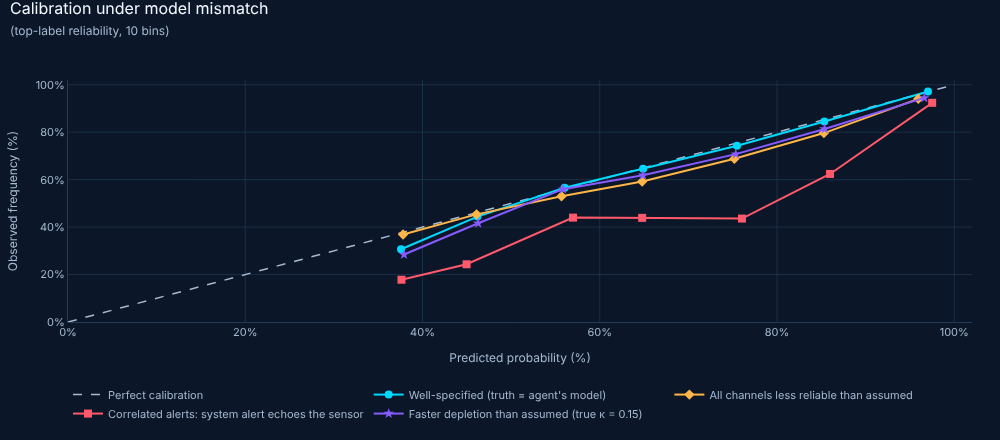

**Experimental result (synthetic).** Well-specified: log loss 0.384, ECE 0.005, cost 1,297 SCU. The largest loss of belief quality occurs for *All channels less reliable than assumed* (log loss 0.638, ECE 0.036). The largest cost occurs for *Faster depletion than assumed (true κ = 0.15)* (2,165 SCU, +67% versus well-specified).

In [39]:
selected = ["Well-specified (truth = agent's model)", "All channels less reliable than assumed",
            "Correlated alerts: system alert echoes the sensor", "Faster depletion than assumed (true κ = 0.15)"]
show(viz.fig_calibration_multi({k: mismatch_calibration[k] for k in selected},
                               "Calibration under model mismatch (top-label reliability, 10 bins)"),
     "25_calibration_mismatch")

base = mismatch_table.iloc[0]
worst_ll = mismatch_table.iloc[mismatch_table["Log loss"].idxmax()]
worst_cost = mismatch_table.iloc[mismatch_table[f"Agent total cost ({COST_UNIT})"].idxmax()]
display(Markdown(
    f"**Experimental result (synthetic).** Well-specified: log loss {base['Log loss']:.3f}, ECE {base['ECE']:.3f}, "
    f"cost {base[f'Agent total cost ({COST_UNIT})']:,.0f} {COST_UNIT}. The largest loss of belief quality occurs for "
    f"*{worst_ll['True environment']}* (log loss {worst_ll['Log loss']:.3f}, ECE {worst_ll['ECE']:.3f}). The largest cost "
    f"occurs for *{worst_cost['True environment']}* ({worst_cost[f'Agent total cost ({COST_UNIT})']:,.0f} {COST_UNIT}, "
    f"{worst_cost[f'Agent total cost ({COST_UNIT})'] / base[f'Agent total cost ({COST_UNIT})'] - 1:+.0%} versus well-specified)."))

**Interpretation.**

- **Overestimated reliability** makes the agent overconfident: it trusts alerts more than they deserve. Belief accuracy, Brier score and log loss all deteriorate, most of all when every channel is worse than assumed, and the reliability curve drops below the diagonal at high confidence.
- **Correlated alerts** reproduce, at scale, the double counting of Section 6.5, and they produce by far the largest calibration error. The system alert adds no information beyond the sensor, yet the agent multiplies both likelihoods. In the chart, when the agent claims about 75% confidence, it is right less than half the time. The cost penalty is small here only because an unnecessary intervention is cheap relative to a stock-out in this cost model; the belief itself is badly miscalibrated.
- **Mis-specified dynamics** (faster depletion, an unreliable supplier) hurt mainly through *cost*. The environment itself is harsher, so the oracle's cost rises as well, and the agent's predictions are too optimistic about how its actions will work.
- In every case the filter keeps producing valid probabilities and sensible actions. Performance degrades gradually; it does not collapse.

The practical message is that a belief-state system is only as trustworthy as its model. Reliabilities, correlations between channels and transition rates would need to be estimated from data and monitored for drift before any real use.

### 9.6 Sensitivity analysis

Two parameters are swept, with the agent's model kept equal to the truth at each setting: (a) sensor reliability, and (b) the stock-out penalty.

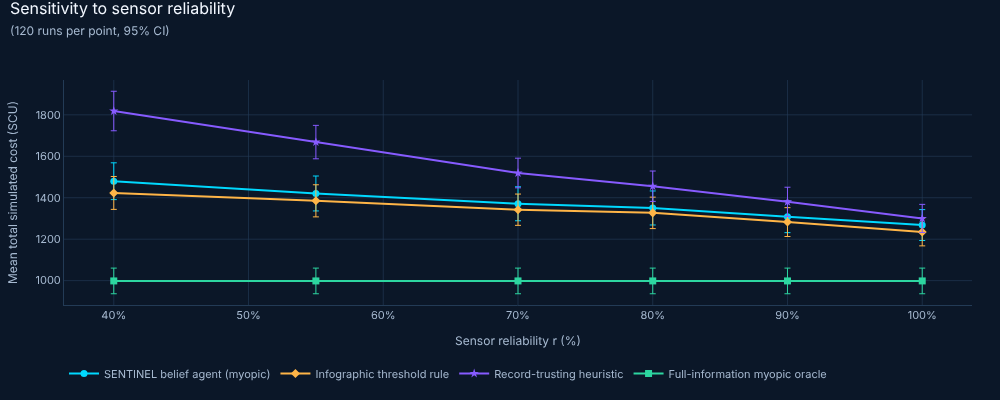

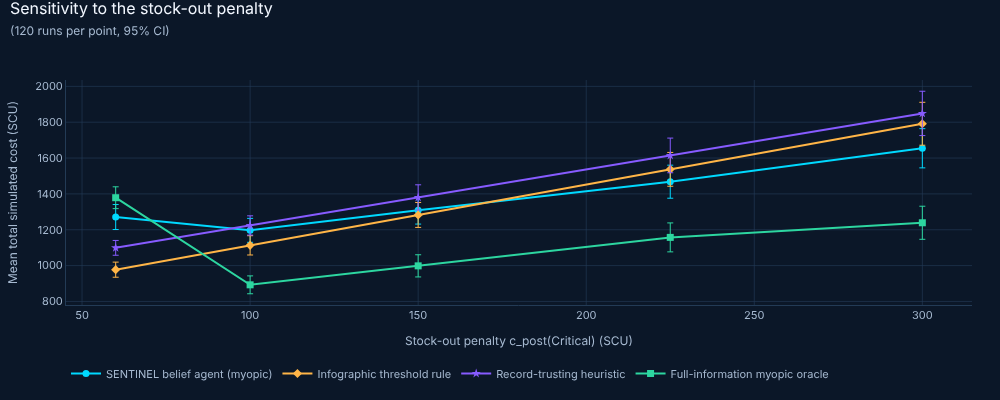

In [40]:
SENS_REPS = 120
sens_policies = {AGENT: policy_factories[AGENT], "Infographic threshold rule": policy_factories["Infographic threshold rule"],
                 RECORD: policy_factories[RECORD], ORACLE: policy_factories[ORACLE]}


def sweep(parameter_values, apply):
    rows = []
    for value in parameter_values:
        config = cfg.copy()
        apply(config, value)
        res = evaluate_policies(config, sens_policies, n_replications=SENS_REPS, horizon=HORIZON, seed=SEED)
        for name, group in res.groupby("policy", sort=False):
            ci = mean_confidence_interval(group["total_cost"])
            rows.append({"value": value, "policy": name, "total_cost": ci["mean"], "ci": ci["half_width"]})
    return pd.DataFrame(rows)


def set_sensor(config, r):
    config.reliability["sensor"] = r


def set_penalty(config, penalty):
    config.post_state_cost = np.array([cfg.post_state_cost[0], cfg.post_state_cost[1], penalty])


sens_reliability = sweep([0.4, 0.55, 0.7, 0.8, 0.9, 1.0], set_sensor)
sens_penalty = sweep([60, 100, 150, 225, 300], set_penalty)

show(viz.fig_lines_with_bands(sens_reliability, "value", "policy", "total_cost", "ci",
                              f"Sensitivity to sensor reliability ({SENS_REPS} runs per point, 95% CI)",
                              "Sensor reliability r (%)", f"Mean total simulated cost ({COST_UNIT})", percent_x=True),
     "26_sensitivity_reliability")
show(viz.fig_lines_with_bands(sens_penalty, "value", "policy", "total_cost", "ci",
                              f"Sensitivity to the stock-out penalty ({SENS_REPS} runs per point, 95% CI)",
                              f"Stock-out penalty c_post(Critical) ({COST_UNIT})",
                              f"Mean total simulated cost ({COST_UNIT})"), "27_sensitivity_penalty")

In [41]:
def pivot(frame, label):
    wide = frame.pivot(index="value", columns="policy", values="total_cost")[list(sens_policies)]
    wide.index.name = label
    wide["Agent vs record-trusting"] = wide[RECORD] / wide[AGENT] - 1
    wide["Agent vs threshold rule"] = wide["Infographic threshold rule"] / wide[AGENT] - 1
    return wide


fmt = {c: "{:,.0f}" for c in sens_policies} | {"Agent vs record-trusting": "{:+.1%}", "Agent vs threshold rule": "{:+.1%}"}
print("Mean total cost by sensor reliability (positive % = the other policy is dearer than the agent)")
display(pivot(sens_reliability, "Sensor reliability").style.format(fmt))
print("Mean total cost by stock-out penalty")
display(pivot(sens_penalty, f"Stock-out penalty ({COST_UNIT})").style.format(fmt))

Mean total cost by sensor reliability (positive % = the other policy is dearer than the agent)


policy,SENTINEL belief agent (myopic),Infographic threshold rule,Record-trusting heuristic,Full-information myopic oracle,Agent vs record-trusting,Agent vs threshold rule
Sensor reliability,,,,,,
0.400000,"1,480","1,423","1,818",999,+22.9%,-3.8%
0.550000,"1,421","1,385","1,669",999,+17.5%,-2.5%
0.700000,"1,371","1,342","1,519",999,+10.8%,-2.1%
0.800000,"1,351","1,327","1,456",999,+7.8%,-1.7%
0.900000,"1,308","1,283","1,380",999,+5.5%,-2.0%
1.000000,"1,268","1,235","1,300",999,+2.5%,-2.6%


Mean total cost by stock-out penalty


policy,SENTINEL belief agent (myopic),Infographic threshold rule,Record-trusting heuristic,Full-information myopic oracle,Agent vs record-trusting,Agent vs threshold rule
Stock-out penalty (SCU),,,,,,
60,"1,271",977,"1,099","1,379",-13.5%,-23.1%
100,"1,197","1,113","1,224",893,+2.3%,-7.0%
150,"1,308","1,283","1,380",999,+5.5%,-2.0%
225,"1,468","1,537","1,615","1,157",+10.0%,+4.7%
300,"1,655","1,791","1,849","1,239",+11.8%,+8.3%


**Interpretation.**

- **Sensor reliability.** The oracle is flat, because it does not need the sensor. The record-trusting heuristic deteriorates quickly as the sensor gets worse, since it has no way to discount a bad reading. The belief agent degrades gently: it automatically leans on the other three channels and on its transition model as the sensor loses value. The advantage of belief-state reasoning over trusting the record is largest exactly where observations are poor, which is the situation the assignment describes. The threshold rule, which uses the same belief, stays within a few percent of the agent at every reliability; the robustness comes from the belief, not from the action rule.
- **Stock-out penalty.** The cost-based rule re-derives its decision boundaries at every setting, while the infographic's 20% / 40% thresholds stay fixed. When stock-outs are expensive, the adaptive rule is clearly cheaper than both the fixed thresholds and the record-trusting heuristic. Around the default penalty, the two belief-based rules are close. When stock-outs are **cheap**, the one-step rule becomes too passive: a single period's expected saving no longer justifies reordering from Low, so stock is allowed to slide into Critical, where it tends to stay. The fixed thresholds then do better, and the myopic *oracle* does worst of all, because certainty about being in Low makes it wait every time. Full information does not cure a short planning horizon.

That last result is the clearest evidence in this notebook that the one-step policy is **not** an optimal POMDP policy. It is the right tool when a transparent, explainable rule is wanted and the cost of a bad state is high relative to the cost of acting; a longer-horizon planner (Section 12.2) is the remedy elsewhere. All rankings are conditional on the synthetic parameters.

## 10. Data visualisations

The assignment lists ten required visualisations. Most have already appeared where they support the argument; this section adds the time-series views of one representative simulated episode and then indexes all ten.

### 10.1 One simulated episode in detail

The following figures show a single 60-period episode of the belief agent (seed 42). The hidden state is shown for evaluation only.

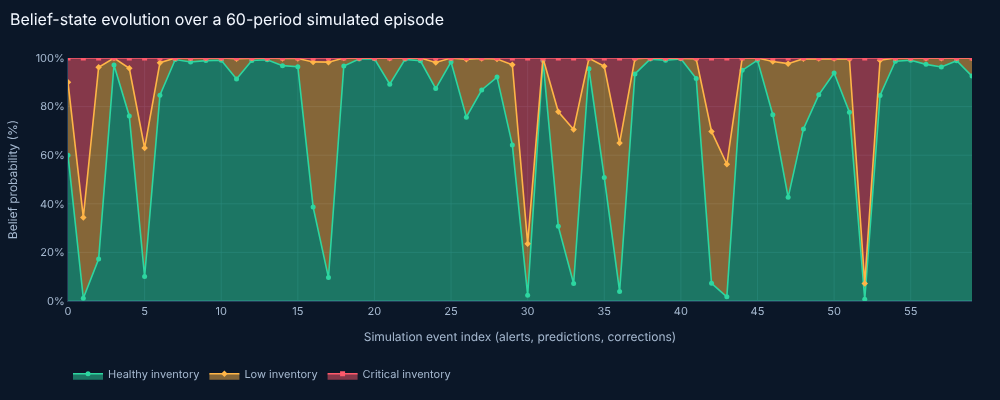

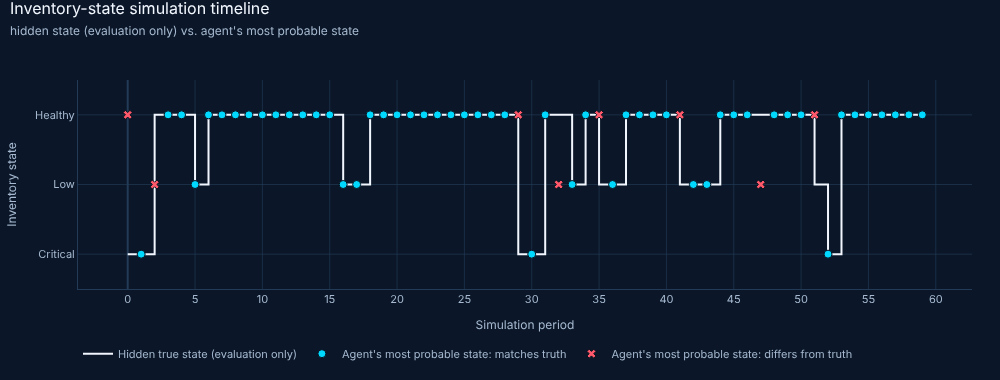

In [42]:
episode = run_episode(cfg, BeliefMyopicPolicy(agent_models.transition, agent_models.cost), horizon=HORIZON, seed=SEED)
episode_timeline = pd.DataFrame({
    "event_index": episode["step"], "period": episode["step"],
    "timestamp": pd.Timestamp("2026-11-11 08:00") + pd.to_timedelta(episode["step"], unit="D"),
    "label": "Belief when the action was chosen", "kind": "predict",
    "b_healthy": episode["b_healthy"], "b_low": episode["b_low"], "b_critical": episode["b_critical"],
    "recommended": episode["action"], "recommended_name": episode["action_name"],
})
show(viz.fig_belief_evolution(episode_timeline, "Belief-state evolution over a 60-period simulated episode"),
     "28_episode_belief_evolution")
show(viz.fig_state_timeline(episode, "Inventory-state simulation timeline: hidden state (evaluation only) vs. agent's most probable state"),
     "29_episode_state_timeline")

**Interpretation.** In the first chart, the belief is mostly green, with amber and coral episodes when adverse evidence arrives; after each intervention the green band recovers. The second chart compares the hidden truth (white line) with the agent's most probable state (markers; a × marks a period where they differ). The agent tracks the truth closely but not perfectly: it typically lags by a period at transitions, because it needs evidence before it can change its mind, and it is occasionally misled by a noisy reading. That residual error is the price of partial observability.

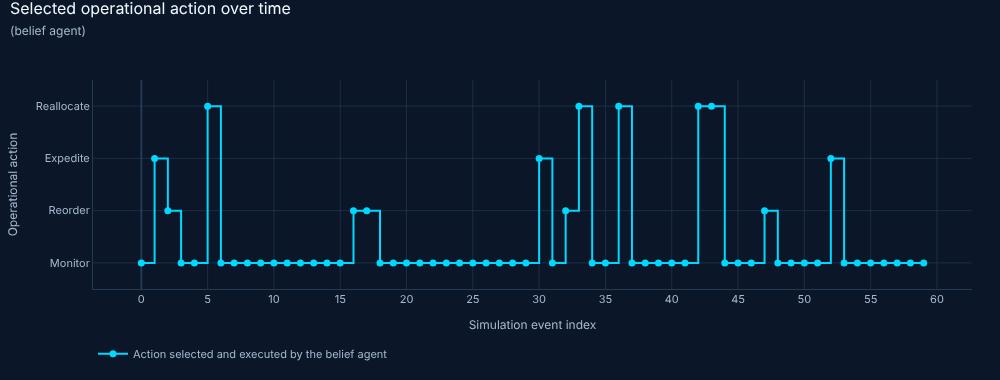

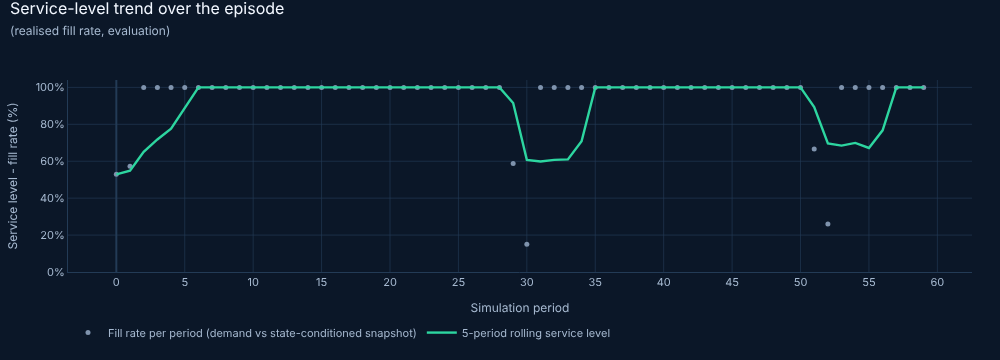

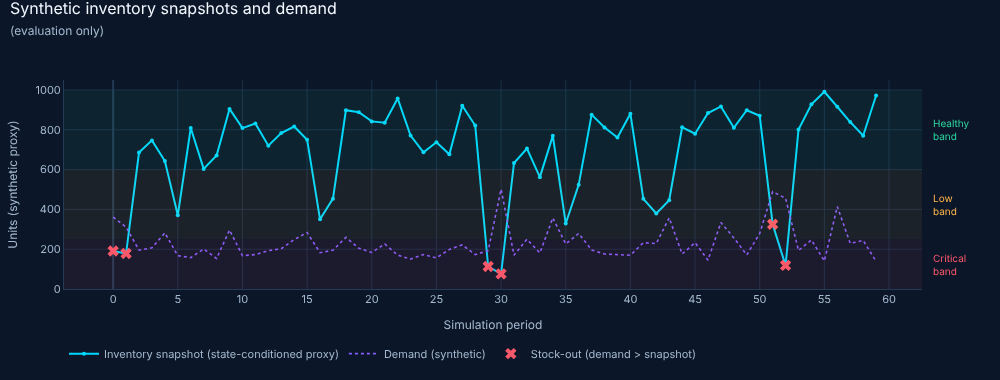

,Episode summary (synthetic)
Total realised cost,"1,307 SCU"
Stock-out periods,6 of 60
Service level (fill rate),90.6%
Policy changes,20
Periods with an intervention,13
Belief accuracy,86.7%


In [43]:
show(viz.fig_policy_timeline(episode_timeline, None, "Selected operational action over time (belief agent)",
                             line_name="Action selected and executed by the belief agent"),
     "30_episode_policy_history")
show(viz.fig_service_trend(episode, "Service-level trend over the episode (realised fill rate, evaluation)"),
     "31_episode_service_level")
show(viz.fig_inventory_units(episode), "32_episode_inventory_units")
episode_summary = {
    "Total realised cost": f"{episode['cost'].sum():,.0f} {COST_UNIT}",
    "Stock-out periods": f"{int(episode['stockout'].sum())} of {len(episode)}",
    "Service level (fill rate)": f"{episode['units_served'].sum() / episode['demand_units'].sum():.1%}",
    "Policy changes": int((episode["action"].diff().fillna(0) != 0).sum()),
    "Periods with an intervention": int((episode["action"] != 0).sum()),
    "Belief accuracy": f"{map_accuracy(episode[BELIEF_COLUMNS].to_numpy(), episode['hidden_state'].to_numpy()):.1%}",
}
display(pd.Series(episode_summary, name="Episode summary (synthetic)").to_frame())

**Interpretation.** The action chart shows a policy that is mostly idle and intervenes in short bursts, each triggered by a shift in belief. The service-level chart shows where those interventions were too late: fill rate drops only in periods whose hidden state was Critical, or Low with a demand surge. The units chart plots the **synthetic inventory snapshots** behind those fill rates. Each is drawn independently inside the hidden state's band, so the line jumps between bands when the state changes and wanders randomly within a band otherwise; it is not a stock balance and should not be read as depletion or replenishment of physical units. Taken together, the charts connect evidence → belief → action → hidden state → service proxy.

### 10.2 Index of the required visualisations

| # | Required visualisation | Where it appears |
|---|---|---|
| 1 | Initial inventory-state distribution | Section 4.3 |
| 2 | Belief-state evolution over time | Sections 8 (Scenario G) and 10.1 |
| 3 | Probability distribution before and after alerts | Sections 6.4, 6.5 and every scenario in Section 8 |
| 4 | State transition probability heatmap | Section 4.4 |
| 5 | Observation likelihood heatmap | Section 4.5 (four channels) |
| 6 | Expected action-cost comparison | Section 7.2 |
| 7 | Recommended operational actions over time | Sections 8 (Scenario G) and 10.1 |
| 8 | Inventory-state simulation timeline | Section 10.1 |
| 9 | Performance comparison between intelligent and baseline policies | Section 9.3 |
| 10 | Simulation evaluation and calibration | Sections 9.4 and 9.5 |

Every chart has a title, labelled axes with units, a legend where there is more than one series, and percentages shown as percentages. PNG copies are saved in `outputs/charts/` when static export is available.

## 11. Discussion and interpretation

**How the belief state evolves.** Two forces act on it. *Prediction* spreads and shifts probability according to the executed action: under monitoring the belief drifts towards Low and Critical, and under replenishment it moves back towards Healthy. *Correction* sharpens it: evidence concentrates probability on the states that explain it best. A period with no informative evidence leaves the belief more uncertain than before, and a period with strong evidence leaves it more certain.

**Which observations have the greatest influence.** Influence is governed by the likelihood ratio between states and by reliability. Sensor readings and system alerts have strong diagonals and high reliability, so a single critical warning can move P(Critical) by tens of percentage points. Supplier updates and demand signals are flatter and less reliable; they nudge the belief. Malfunction symbols have a likelihood ratio of exactly 1 and do nothing. An alert with reliability 0 does nothing either.

**Why the same alert may produce different actions.** An alert multiplies the prior by a likelihood; it does not replace the prior. Section 7.5 showed one supplier delay leaving the recommendation unchanged, tipping it to a reorder, or pushing it to reallocation, depending only on the prior. The policy map makes this geometric: an alert moves the belief point, and the action changes only if the point crosses a region boundary.

**How supplier delays affect the model.** They affect it in two ways. As *evidence*, a delay raises the probability of Low and Critical inventory because delays and depletion tend to occur together. As a *model parameter* (supplier risk $\rho$), an unreliable supplier weakens the transition effect of reorder and expedite, which shifts the policy towards reallocation, the action that does not depend on the supplier. Section 9.5 showed the cost of the agent being unaware of the second effect.

**How uncertainty influences operational expenditure.** Uncertainty has a price. At the default costs, the oracle spends less than every implementable policy because it knows the true state: it never orders when stock is already Healthy and never misses a Critical period. The belief agent pays for some avoidable stock-outs and some avoidable orders. Better information (higher reliability) narrows that gap, which gives a way to value a sensor upgrade: it is worth up to the cost difference it removes (Section 9.6).

**Why an intelligent agent may monitor instead of ordering immediately.** Ordering has a certain cost and an uncertain benefit. When most probability is on Healthy, the expected shortage cost avoided by ordering is smaller than the order's direct and surplus cost, so waiting is the rational choice. Monitoring is a decision with its own expected cost, compared on equal terms with the other three.

**The importance of sensor reliability.** Reliability decides how much a reading should count. Treating an unreliable reading as fact (the record-trusting heuristic) leads to false alarms and missed shortages; ignoring a reliable reading wastes information. Modelling reliability explicitly lets the agent weight each alert correctly, and assuming the wrong reliability makes it measurably overconfident (Section 9.5).

**Limitations of the decision policy.** The policy is myopic. It optimises the next period only, which makes it transparent and cheap but means it under-reacts when a bad state is persistent, and it never chooses an action *in order to learn*. Section 9.3 shows the size of the first effect at the default parameters (QMDP and the fixed-threshold rule are a few percent cheaper), and Section 9.6 shows it becoming severe when stock-outs are cheap. The second effect cannot appear at all here, because no action in the model changes what will be observed.

## 12. Limitations and future improvements

### 12.1 Limitations

| Limitation | Why it matters |
|---|---|
| **Reliance on synthetic data** | Every probability and cost is assumed. The results describe the simulator, not any real supply chain. |
| **Assumed transition probabilities** | Real depletion and recovery depend on lead times, order quantities and demand processes that a 3×3 matrix compresses heavily. |
| **Imperfect observation models** | Likelihoods and reliabilities are guesses. Section 9.5 shows that wrong reliabilities make the agent overconfident. |
| **Conditional-independence assumption** | Real alerts are often correlated (one sensor feeds several systems). The duplicate guard handles exact repeats only; cross-channel correlation still causes double counting. |
| **Potential real-world data drift** | Supplier behaviour, demand patterns and sensor quality change over time; a fixed model would silently degrade. |
| **Three-state abstraction** | "Healthy / Low / Critical" hides the actual quantity. Only the state evolves over time. |
| **Unit figures are state-conditioned snapshots** | Inventory units are drawn independently within the current state's band (Healthy [600, 1,000], Low [250, 600), Critical [0, 250)) each period, with no roll-forward balance (stock − demand + deliveries). Stock-out frequency, fill rate and service level are therefore per-period proxies driven by the hidden state, not outputs of a physically continuous inventory simulation, and order quantities and lead times are not modelled in units. |
| **Stationarity** | Transition and observation models do not vary with season, promotions or day of week. |
| **Computational limitations** | Exact POMDP planning is intractable in general (Papadimitriou & Tsitsiklis, 1987). This small model avoids the issue by planning one step ahead. |
| **Myopic versus long-horizon optimisation** | The one-step rule ignores future costs and the value of information. In inventory with inaccurate records, forward-looking and myopic managers are known to stock differently (Mersereau, 2013). |
| **Scalability** | One item at one location. A real network has thousands of items, shared suppliers and transshipment, and the joint belief grows exponentially. |
| **Evaluation inside the agent's own model** | Calibration in the well-specified simulator verifies the code, not the model. |

### 12.2 Future improvements

1. **Real supplier and sensor integrations.** Estimate $T$ and $Z$ from logged data (for example with the Baum–Welch / EM algorithm for hidden Markov models) and monitor calibration online to detect drift.
2. **Predictive demand modelling.** Replace the four-level demand signal with a forecast distribution, and let demand be its own hidden factor.
3. **An explicit information-gathering action.** Add "physical count / audit" with a cost and a highly informative observation, in the spirit of the joint inspection and replenishment policies of Kök and Shang (2007). This is where a myopic and a forward-looking policy should diverge.
4. **More advanced POMDP planning.** With only three states, the belief simplex is a triangle, so finite-horizon lookahead, exact value iteration over alpha-vectors, or point-based solvers such as SARSOP (Kurniawati et al., 2008) are all feasible and would quantify the value of information that the present policy ignores.
5. **Hierarchical inventory management.** Item-level agents under a location-level budget, with aggregate service constraints.
6. **Multi-agent supply-chain coordination.** Agents for suppliers, warehouses and stores that share beliefs and negotiate reallocation.
7. **Correlation-aware evidence fusion.** Model shared noise sources between channels explicitly instead of assuming independence.

## 13. Final conclusion

### 13.1 Notebook–dashboard numerical cross-check

The dashboard and this notebook import the same engine. To demonstrate that they agree, three identical alert scenarios are computed twice here: once with the low-level functions used throughout this notebook (`predict`, `correct`, `evaluate_actions`; no engine object) and once through `SentinelEngine.play_scenario`, which is exactly what the dashboard's **Load scenario** button calls. The notebook's numbers are saved to `outputs/cross_check_notebook.json`; the automated test `tests/test_integration.py` then drives the real dashboard script headlessly and asserts that its numbers match that file.

In [44]:
cross_check, saved = [], {}
for key in CROSS_CHECK_SCENARIOS:
    notebook_side = replay_with_primitives(SCENARIOS[key], cfg)                  # notebook maths, no engine
    engine = SentinelEngine(cfg)
    engine.play_scenario(SCENARIOS[key])                                         # what the dashboard runs
    update = engine.bayes_breakdown()
    dashboard_side = {"prior": update.prior, "predicted": update.predicted, "joint_likelihood": update.joint_likelihood,
                      "posterior": update.posterior, "q_values": engine.decision.q_values,
                      "action": int(engine.decision.action)}
    gaps = {name: float(np.abs(np.asarray(notebook_side[name]) - np.asarray(dashboard_side[name])).max())
            for name in ("prior", "predicted", "joint_likelihood", "posterior", "q_values")}
    assert max(gaps.values()) < 1e-10 and notebook_side["action"] == dashboard_side["action"]
    cross_check.append({
        "Scenario": SCENARIOS[key].name, "Prior (H / L / C)": format_belief(notebook_side["prior"]),
        "Predicted (H / L / C)": format_belief(notebook_side["predicted"]),
        "Joint likelihood (H, L, C)": ", ".join(f"{v:.5f}" for v in notebook_side["joint_likelihood"]),
        "Posterior (H / L / C)": format_belief(notebook_side["posterior"]),
        f"Expected cost by action ({COST_UNIT})": ", ".join(f"{q:.2f}" for q in notebook_side["q_values"]),
        "Recommended action": ACTIONS[notebook_side["action"]], "Largest absolute difference": max(gaps.values())})
    saved[key] = {name: np.asarray(value).tolist() if name != "action" else int(value)
                  for name, value in notebook_side.items()}

(ROOT / "outputs").mkdir(exist_ok=True)
(ROOT / "outputs" / "cross_check_notebook.json").write_text(json.dumps(saved, indent=2))
display(pd.DataFrame(cross_check).style.hide(axis="index").format({"Largest absolute difference": "{:.1e}"}))
print("Notebook and engine agree on all six quantities for all three scenarios (tolerance 1e-10).")
print("Saved outputs/cross_check_notebook.json for the dashboard test.")

Scenario,Prior (H / L / C),Predicted (H / L / C),"Joint likelihood (H, L, C)",Posterior (H / L / C),Expected cost by action (SCU),Recommended action,Largest absolute difference
Unexpected Supplier Delay,37.0% / 40.2% / 22.8%,57.9% / 29.4% / 12.7%,"0.00625, 0.05160, 0.03371",15.7% / 65.7% / 18.6%,"60.81, 44.60, 54.09, 44.84",Standard Reorder,0.0e+00
Conflicting Sensor Evidence,60.0% / 30.0% / 10.0%,60.0% / 30.0% / 10.0%,"0.00112, 0.00091, 0.00149",61.4% / 25.0% / 13.6%,"37.08, 37.70, 55.19, 40.46",Continue Monitoring,0.0e+00
Successful Replenishment and Recovery,98.4% / 1.6% / 0.0%,83.7% / 13.9% / 2.4%,"0.74500, 0.16000, 0.06100",96.3% / 3.4% / 0.2%,"10.75, 27.89, 55.19, 34.20",Continue Monitoring,0.0e+00


Notebook and engine agree on all six quantities for all three scenarios (tolerance 1e-10).
Saved outputs/cross_check_notebook.json for the dashboard test.


### 13.2 Summary

**Assignment objective.** Show how an AI agent updates its belief state and changes its decision policy when new alerts are received, for inventory management under uncertainty.

**Implementation.** A three-state hidden inventory POMDP with four actions and four observation channels; an exact two-stage Bayes filter with joint, log-space correction and reliability-adjusted likelihoods; a transition-dependent cost model; a myopic expected-cost policy with generated explanations; a hidden-state simulator; and an evaluation suite. All of it lives in one shared Python package used by both this notebook and the dashboard.

**Mathematical findings (derivations and synthetic experiments).**

- Prediction and correction are distinct operations with distinct effects on uncertainty, and simultaneous alerts must be fused in one correction after one prediction.
- $Q(b, a)$ is linear in the belief, so each action is optimal on a convex region of the simplex. Decision thresholds are consequences of the cost model.
- The same alert can lead to different actions under different priors, and an alert's influence scales with its likelihood ratio and reliability.
- In the synthetic simulator, the belief agent clearly outperforms evidence-blind and record-trusting policies and degrades gracefully as sensors worsen. It is a few percent dearer than QMDP and the infographic's threshold rule at the default costs, becomes too passive when stock-outs are cheap, and remains well short of a full-information oracle.
- Counting correlated evidence as independent, or overstating reliability, makes the belief measurably overconfident.

**Practical relevance.** Stock records are known to be unreliable in practice (DeHoratius & Raman, 2008), and a Bayesian belief over physical inventory is an established response (DeHoratius et al., 2008). A belief-state decision-support tool gives a planner three things a record-based system cannot: an explicit statement of uncertainty, a recommendation whose rationale is expressed in costs and probabilities, and a principled way to weigh alerts of different quality.

### 13.3 How the system satisfies the requested POMDP workflow

| Stage in the professor's infographic | Where SENTINEL implements it |
|---|---|
| 1. Real-world environment (true state hidden) | `InventoryEnvironment`: hidden state plus synthetic unit snapshots for evaluation, exposed to the agent only through observations (Sections 2, 5) |
| 2. Partial observation | Four channels with likelihood matrices and reliabilities (Section 4.5) |
| 3. Belief-state estimation | Two-stage Bayes filter, starting from $b_0 = [0.60, 0.30, 0.10]$ (Section 6) |
| 4. Decision policy | Expected-cost evaluation of all four actions, arg-min selection, explanation (Section 7) |
| 5. Operational action | Recommended versus executed actions; only executed actions drive transitions (Sections 4.1, 8) |
| 6. Reward or cost evaluation | $C(s,a,s')$ with $R = -C$; expected cost for decisions, realised cost for evaluation (Sections 4.6, 9) |
| 7. Repeated belief updates as new information arrives | Scenario and episode simulations; the dashboard's live loop (Sections 8, 10) |

The dashboard runs this same loop interactively: inject an alert and the belief, the expected costs, NOVA's explanation and the recommendation all update from the same functions used above.

## References

Åström, K. J. (1965). Optimal control of Markov processes with incomplete state information. *Journal of Mathematical Analysis and Applications, 10*(1), 174–205. https://doi.org/10.1016/0022-247X(65)90154-X

Brier, G. W. (1950). Verification of forecasts expressed in terms of probability. *Monthly Weather Review, 78*(1), 1–3. https://doi.org/10.1175/1520-0493(1950)078<0001:VOFEIT>2.0.CO;2

DeHoratius, N., Mersereau, A. J., & Schrage, L. (2008). Retail inventory management when records are inaccurate. *Manufacturing & Service Operations Management, 10*(2), 257–277. https://doi.org/10.1287/msom.1070.0203

DeHoratius, N., & Raman, A. (2008). Inventory record inaccuracy: An empirical analysis. *Management Science, 54*(4), 627–641. https://doi.org/10.1287/mnsc.1070.0789

Domingos, P., & Pazzani, M. (1997). On the optimality of the simple Bayesian classifier under zero-one loss. *Machine Learning, 29*(2–3), 103–130. https://doi.org/10.1023/A:1007413511361

Gneiting, T., & Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association, 102*(477), 359–378. https://doi.org/10.1198/016214506000001437

Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. *Proceedings of the 34th International Conference on Machine Learning* (Proceedings of Machine Learning Research, Vol. 70, pp. 1321–1330). https://proceedings.mlr.press/v70/guo17a.html

Huber, P. J. (1964). Robust estimation of a location parameter. *The Annals of Mathematical Statistics, 35*(1), 73–101. https://doi.org/10.1214/aoms/1177703732

Kaelbling, L. P., Littman, M. L., & Cassandra, A. R. (1998). Planning and acting in partially observable stochastic domains. *Artificial Intelligence, 101*(1–2), 99–134. https://doi.org/10.1016/S0004-3702(98)00023-X

Kochenderfer, M. J., Wheeler, T. A., & Wray, K. H. (2022). *Algorithms for decision making*. MIT Press. https://algorithmsbook.com

Kök, A. G., & Shang, K. H. (2007). Inspection and replenishment policies for systems with inventory record inaccuracy. *Manufacturing & Service Operations Management, 9*(2), 185–205. https://doi.org/10.1287/msom.1060.0136

Kurniawati, H., Hsu, D., & Lee, W. S. (2008). SARSOP: Efficient point-based POMDP planning by approximating optimally reachable belief spaces. In *Robotics: Science and Systems IV*. https://doi.org/10.15607/RSS.2008.IV.009

Littman, M. L., Cassandra, A. R., & Kaelbling, L. P. (1995). Learning policies for partially observable environments: Scaling up. In A. Prieditis & S. Russell (Eds.), *Proceedings of the Twelfth International Conference on Machine Learning* (pp. 362–370). Morgan Kaufmann. https://doi.org/10.1016/B978-1-55860-377-6.50052-9

Mersereau, A. J. (2013). Information-sensitive replenishment when inventory records are inaccurate. *Production and Operations Management, 22*(4), 792–810. https://doi.org/10.1111/j.1937-5956.2011.01305.x

Niculescu-Mizil, A., & Caruana, R. (2005). Predicting good probabilities with supervised learning. In *Proceedings of the 22nd International Conference on Machine Learning* (pp. 625–632). Association for Computing Machinery. https://doi.org/10.1145/1102351.1102430

Papadimitriou, C. H., & Tsitsiklis, J. N. (1987). The complexity of Markov decision processes. *Mathematics of Operations Research, 12*(3), 441–450. https://doi.org/10.1287/moor.12.3.441

Ross, S., Pineau, J., Paquet, S., & Chaib-draa, B. (2008). Online planning algorithms for POMDPs. *Journal of Artificial Intelligence Research, 32*, 663–704. https://doi.org/10.1613/jair.2567

Silver, E. A., Pyke, D. F., & Thomas, D. J. (2017). *Inventory and production management in supply chains* (4th ed.). CRC Press.

Smallwood, R. D., & Sondik, E. J. (1973). The optimal control of partially observable Markov processes over a finite horizon. *Operations Research, 21*(5), 1071–1088. https://doi.org/10.1287/opre.21.5.1071

Thrun, S., Burgard, W., & Fox, D. (2005). *Probabilistic robotics*. MIT Press.

*Reference status.* Bibliographic details were checked against publisher or library records. Empirical statements attributed to these sources are limited to what their abstracts state. All parameters and results in this notebook are synthetic and are not drawn from any of these works.